# Movement magnitude and direction

Separate barrier-hit probability, expected movement magnitude and directional efficiency.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Energy.ipynb`, original cells 0–161 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


In [ ]:
import polars as pl

df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L.parquet")))

In [ ]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'ac

# Add Barrier

## Core TB barrier labeler (y in {-1,0,+1})

In [ ]:
from __future__ import annotations
from dataclasses import dataclass
from typing import Iterable, Sequence, Optional, Dict, Any, Tuple, List
import numpy as np
import polars as pl

In [ ]:
def add_tb_label_dynamic_range(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    close_col: str = "close",
    high_col: str = "high",
    low_col: str = "low",
    missing_col: str = "is_missing_fill",
    # scale estimator
    rr_win: int = 480,
    rr_min_periods: int = 50,
    rr_use_bps: bool = True,
    rr_quantile: Optional[float] = None,  # None -> rolling median, else rolling quantile (e.g., 0.7, 0.8)
    clamp_q: Optional[Tuple[float, float]] = (0.05, 0.95),  # clamp scale to robust bounds (computed on scale series)
    # barrier scaling
    H: int = 30,
    k: float = 5.0,
    alpha: float = 0.5,  # width scales ~ H^alpha
    # outputs
    out_col: str = "y_tb",
    tie_to_nan: bool = True,
) -> Tuple[pl.DataFrame, pl.DataFrame]:
    """
    Triple-barrier-style directional hit label:
      +1 if future high hits U first
      -1 if future low hits L first
       0 if neither within H
      tie: if both hit in same bar => NaN (or 0 if tie_to_nan=False)
    Barriers:
      dist = base_scale * k * (H ** alpha)
      U = close + dist, L = close - dist
    base_scale = rolling median/quantile of 1-min realized range (high-low), optionally in bps.

    Returns:
      (df_with_cols, report_df)
    """
    df = df.sort(tcol)

    # realized range proxy (1-bar)
    rr = (pl.col(high_col) - pl.col(low_col)).cast(pl.Float64)
    if rr_use_bps:
        rr = (rr / pl.col(close_col) * 1e4).alias("_rr")
    else:
        rr = rr.alias("_rr")

    df = df.with_columns(rr)

    # rolling robust base scale
    if rr_quantile is None:
        base = pl.col("_rr").rolling_median(window_size=rr_win, min_samples=rr_min_periods)
    else:
        base = pl.col("_rr").rolling_quantile(
            quantile=float(rr_quantile),
            window_size=rr_win,
            min_samples=rr_min_periods,
            interpolation="nearest",
        )

    base = pl.when(pl.col(missing_col)).then(pl.lit(None)).otherwise(base).alias("_rr_base")
    df = df.with_columns(base)

    # clamp base scale if requested
    if clamp_q is not None:
        qlo, qhi = clamp_q
        # compute global-ish clamp bounds on available base (robust). For strict rolling clamp you'd do windowed quantiles.
        # This is simple + stable and avoids pathologically tiny/huge widths.
        base_vals = df.select(pl.col("_rr_base")).to_series().to_numpy()
        base_finite = base_vals[np.isfinite(base_vals)]
        if base_finite.size > 0:
            lo = np.quantile(base_finite, qlo)
            hi = np.quantile(base_finite, qhi)
        else:
            lo, hi = (np.nan, np.nan)

        df = df.with_columns(
            pl.when(pl.col("_rr_base").is_null())
              .then(pl.lit(None))
              .otherwise(pl.col("_rr_base").clip(lo, hi))
              .alias("_rr_base")
        )

    # numpy arrays for fast path scan
    missing = df[missing_col].to_numpy().astype(bool)
    close = df[close_col].to_numpy().astype(float)
    high  = df[high_col].to_numpy().astype(float)
    low   = df[low_col].to_numpy().astype(float)
    rr_base = df["_rr_base"].to_numpy().astype(float)

    n = len(df)
    y = np.full(n, np.nan, dtype=float)
    tie = np.zeros(n, dtype=bool)

    scale = k * (H ** alpha)

    if rr_use_bps:
        # rr_base is in bps => convert to price distance
        dist = close * (rr_base / 1e4) * scale
        width_bps = 2.0 * rr_base * scale
    else:
        dist = rr_base * scale
        width_bps = (2.0 * dist / close) * 1e4

    U = close + dist
    L = close - dist

    for i in range(n):
        if missing[i] or not np.isfinite(U[i]) or not np.isfinite(L[i]) or (i + H >= n):
            y[i] = np.nan
            continue

        ui, li = U[i], L[i]
        hit = 0.0
        tied = False

        for j in range(i + 1, i + H + 1):
            up = high[j] >= ui
            dn = low[j] <= li
            if up and dn:
                tied = True
                hit = np.nan if tie_to_nan else 0.0
                break
            if up:
                hit = +1.0
                break
            if dn:
                hit = -1.0
                break

        y[i] = hit
        tie[i] = tied

    out = (
        df.with_columns([
            pl.Series("_U", U),
            pl.Series("_L", L),
            pl.Series(out_col, y),
            pl.Series(out_col + "_tie", tie),
            pl.Series(out_col + "_width_bps", width_bps),
        ])
        .drop(["_rr"], strict=False)
    )

    valid = out.filter(pl.col(out_col).is_not_null() & pl.col(out_col).is_finite())

    rep = valid.select([
        (pl.col(out_col).abs() == 1).mean().alias("hit_rate"),
        pl.col(out_col + "_tie").mean().alias("tie_rate"),
        (pl.col(out_col) == 1).mean().alias("up_rate"),
        (pl.col(out_col) == -1).mean().alias("dn_rate"),
        pl.col(out_col + "_width_bps").median().alias("width_bps_median"),
        pl.col(out_col + "_width_bps").quantile(0.90).alias("width_bps_p90"),
        pl.col(out_col).value_counts().alias("label_counts"),
    ])

    return out, rep

In [ ]:
df_labeled, report = add_tb_label_dynamic_range(
    df,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    missing_col="is_missing_fill",

    # scale จาก realized range
    rr_win=480,
    rr_min_periods=50,
    rr_use_bps=True,        # คิดเป็น bps
    rr_quantile=None,       # None = rolling median

    # horizon / threshold
    H=30,
    k=1,
    alpha=0.5,              # sqrt(H)

    out_col="y_tb30",
    tie_to_nan=True,
)

In [ ]:
report

hit_rate,tie_rate,up_rate,dn_rate,width_bps_median,width_bps_p90,label_counts
f64,f64,f64,f64,f64,f64,struct[2]
0.473797,0.0,0.230646,0.24315,96.069837,197.090365,"{1.0,727298}"
0.473797,0.0,0.230646,0.24315,96.069837,197.090365,"{-1.0,766727}"
0.473797,0.0,0.230646,0.24315,96.069837,197.090365,"{0.0,1659280}"


In [ ]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

label_col = "y_tb30"

dfp = (
    df_labeled
    .with_columns([
        # แปลงเวลาให้เป็น Datetime (ถ้าคุณเป็น datetime อยู่แล้ว บรรทัดนี้ไม่จำเป็น)
        pl.col("t").cast(pl.Datetime).alias("t"),
        (pl.col(label_col).abs() == 1).cast(pl.Int8).alias("is_hit"),
        pl.col(label_col + "_width_bps").cast(pl.Float64).alias("width_bps"),
    ])
    .filter(pl.col("is_hit").is_not_null())
)

In [ ]:
wk = (
    dfp
    .group_by_dynamic("t", every="1w", closed="left", label="left")
    .agg([
        pl.mean("is_hit").alias("hit_rate"),
        pl.median("width_bps").alias("width_bps_med"),
        pl.len().alias("n"),
    ])
    .sort("t")
)

wk_pd = wk.to_pandas()

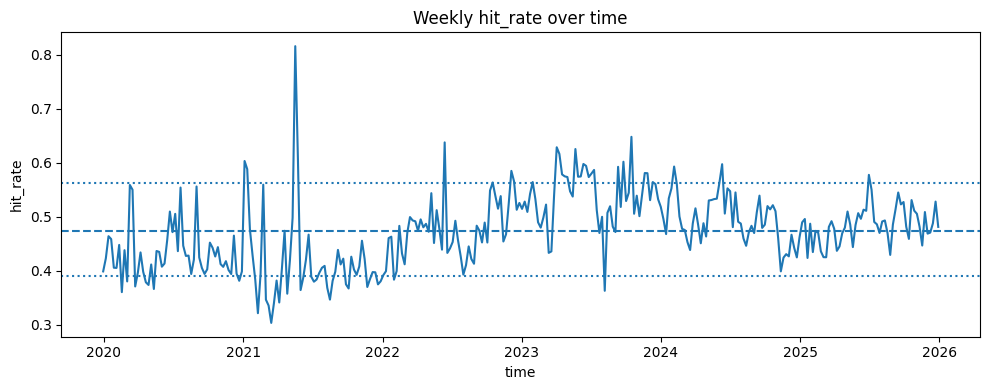

In [ ]:
x = wk_pd["t"]
y = wk_pd["hit_rate"].values

med = np.nanmedian(y)
p10 = np.nanpercentile(y, 10)
p90 = np.nanpercentile(y, 90)

plt.figure(figsize=(10,4))
plt.plot(x, y)
plt.axhline(med, linestyle="--")
plt.axhline(p10, linestyle=":")
plt.axhline(p90, linestyle=":")
plt.title("Weekly hit_rate over time")
plt.xlabel("time")
plt.ylabel("hit_rate")
plt.tight_layout()
plt.show()

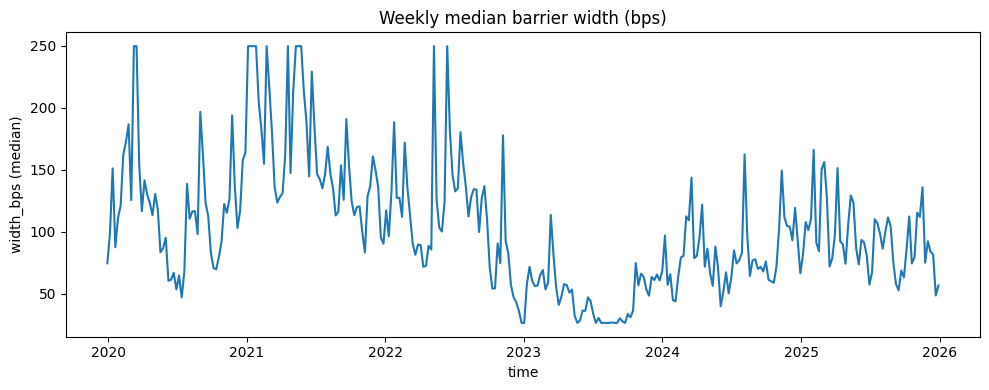

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(x, wk_pd["width_bps_med"].values)
plt.title("Weekly median barrier width (bps)")
plt.xlabel("time")
plt.ylabel("width_bps (median)")
plt.tight_layout()
plt.show()

# Manage Feature

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 12.6 MB/s eta 0:00:00


In [ ]:
import math
import numpy as np
import polars as pl

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    roc_auc_score, f1_score, confusion_matrix,
    precision_score
)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

In [ ]:
def sanity_check_time(df: pl.DataFrame, tcol="t") -> None:
    dt = df.schema[tcol]
    assert dt in (pl.Datetime, pl.Datetime("us"), pl.Datetime("ms"), pl.Datetime("ns")), f"{tcol} dtype is {dt}, not Datetime"
    # sorted?
    t = df[tcol].to_numpy()
    assert np.all(t[1:] >= t[:-1]), f"{tcol} is not monotonic non-decreasing"
sanity_check_time(df)

In [ ]:
# drop missing-fill rows + invalid labels
df_labeled = df_labeled.filter((~pl.col("is_missing_fill")) & pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())

# Drop rows with missing fill or label NaN
df_labeled = df_labeled.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("y_tb30").is_not_null())
)

In [ ]:
df_labeled = df_labeled.with_row_count("i")

/tmp/ipython-input-2539692572.py:1: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df_labeled = df_labeled.with_row_count("i")


In [ ]:
df_labeled.columns

['i',
 't',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120'

In [ ]:
FEATURES = [
    # ─────────────────────────────
    # A) Market Direction / Pressure
    # ─────────────────────────────
    "signed_quote",
    "signed_quote_rank_like_Lint",
    'sq_rank_with_sign',
    'sq_rank_with_sign_rank_ema_5',
    'sq_rank_with_sign_rank_ema_15',
    'sq_rank_with_sign_rank_ema_30',
    'sq_rank_with_sign_rank_ema_60',
    'sq_rank_with_sign_rank_ema_120',
    'sq_rank_with_sign_rank_ema_480',
    'sq_rank_with_sign_rank_ema_1440',
    'sq_rank_with_sign_rank_ema_60_slope_30',
    'sq_rank_with_sign_rank_ema_120_slope_30',
    'sq_rank_with_sign_rank_ema_120_slope_120',
    'sq_rank_with_sign_rank_ema_480_slope_120',
    'signed_quote_evt_pos_frac_60m',
    'signed_quote_evt_neg_frac_60m',
    'signed_quote_evt_frac_60m',
    'signed_quote_evt_pos_frac_240m',
    'signed_quote_evt_neg_frac_240m',
    'signed_quote_evt_frac_240m',
    'signed_quote_evt_pos_frac_480m',
    'signed_quote_evt_neg_frac_480m',
    'signed_quote_evt_frac_480m',

    # ─────────────────────────────
    # B) Activity / Participation
    # ─────────────────────────────
    "active_ms",
    "active_ms_rank_like_Lint",
    'active_ms_rank_ema_15',
    'active_ms_rank_ema_60',
    'active_ms_rank_ema_30',
    'active_ms_rank_ema_120',
    'active_ms_rank_ema_480',
    'active_ms_rank_ema_1440',
    'active_ms_rank_ema_2880',
    'active_ms_rank_ema_120_slope_30',
    'active_ms_rank_ema_120_slope_120',
    'active_ms_rank_ema_480_slope_30',
    'active_ms_rank_ema_480_slope_120',
    'active_ms_rank_ema_1440_slope_120',
    'active_ms_rank_ema_1440_slope_480',
    'active_ms_evt_frac_60m',
    'active_ms_evt_frac_240m',
    'active_ms_evt_frac_480m',


    # ─────────────────────────────
    # C) Trade Size / Commitment
    # ─────────────────────────────
    "avg_trade_q",
    "avg_trade_q_rank_like_Lint",
    'avg_trade_q_rank_ema_15',
    'avg_trade_q_rank_ema_30',
    'avg_trade_q_rank_ema_60',
    'avg_trade_q_rank_ema_120',
    'avg_trade_q_rank_ema_480',
    'avg_trade_q_rank_ema_1440',
    'avg_trade_q_rank_ema_120_slope_30',
    'avg_trade_q_rank_ema_120_slope_120',
    'avg_trade_q_rank_ema_480_slope_30',
    'avg_trade_q_rank_ema_480_slope_120',
    'avg_trade_q_rank_ema_1440_slope_120',
    'avg_trade_q_rank_ema_1440_slope_480',
    'avg_trade_q_evt_frac_60m',
    'avg_trade_q_evt_frac_240m',
    'avg_trade_q_evt_frac_480m',

    # ─────────────────────────────
    # D) Run / Continuity
    # ─────────────────────────────
    "run_mean",
    "run_mean_q_rank_like_Lint",
    "run_max",
    "run_max_evt_frac_60m",
    'run_max_evt_frac_240m',
    'run_max_evt_frac_480m',

    'run_mean_q_rank_ema_15',
    'run_mean_q_rank_ema_30',
    'run_mean_q_rank_ema_60',
    'run_mean_q_rank_ema_120',
    'run_mean_q_rank_ema_480',
    'run_mean_q_rank_ema_1440',
    'run_mean_q_rank_ema_120_slope_30',
    'run_mean_q_rank_ema_120_slope_120',
    'run_mean_q_rank_ema_480_slope_30',
    'run_mean_q_rank_ema_480_slope_120',
    'run_mean_q_rank_ema_1440_slope_120',
    'run_mean_q_rank_ema_1440_slope_480',

    # ─────────────────────────────
    # E) Volatility / Range (TB-aligned)
    # ─────────────────────────────
    "rv_sqrt",
    'rv_sqrt_q_rank_ema_15',
    'rv_sqrt_q_rank_ema_30',
    'rv_sqrt_q_rank_ema_60',
    'rv_sqrt_q_rank_ema_120',
    'rv_sqrt_q_rank_ema_480',
    'rv_sqrt_q_rank_ema_1440',
    'rv_sqrt_q_rank_ema_2880',
    'rv_sqrt_q_rank_ema_120_slope_30',
    'rv_sqrt_q_rank_ema_120_slope_120',
    'rv_sqrt_q_rank_ema_480_slope_30',
    'rv_sqrt_q_rank_ema_480_slope_120',
    'rv_sqrt_q_rank_ema_1440_slope_120',
    'rv_sqrt_q_rank_ema_1440_slope_480',
    'rv_sqrt_ema_15',
    'rv_sqrt_ema_30',
    'rv_sqrt_ema_60',
    'rv_sqrt_ema_120',
    'rv_sqrt_ema_480',
    'rv_sqrt_ema_1440',
    'rv_sqrt_ema_2880',
    'rv_sqrt_evt_frac_60m',
    'rv_sqrt_evt_frac_240m',
    'rv_sqrt_evt_frac_480m',

    # ─────────────────────────────
    # F) Intensity / Burst
    # ─────────────────────────────
    "intensity_peak_1s",
     'intensity_peak_1s_evt_frac_60m',
    'intensity_peak_1s_evt_frac_240m',
    'intensity_peak_1s_evt_frac_480m',

     'realized_range',
      'realized_range_bps',
      'rr_med_120',
      'rr_med_120_bps',
      'rr_med_480',
      'rr_med_480_bps',
      'rr_med_1440',
      'rr_med_1440_bps',
      'rr_mean_30',
      'rr_mean_60',
      'rr_mean_120',
      'rr_mean_480',
      'rr_mean_1440',
]

# Predict ชนขอบ

## Train

In [ ]:
model_df = (
    df_labeled.select(["t", "y_tb30"] + FEATURES)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

In [ ]:
sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3153305 n_features = 117


In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df_bin = make_binary(model_df)

In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

In [ ]:
folds = make_walkforward_splits(
    df,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,      # test ไม่ซ้อน
    mode="rolling",
    purge_minutes=30,
    embargo_minutes=60,
)

In [ ]:
def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

X = (
    df_bin
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)
)

y = df_bin["y_hit"].to_numpy()

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

fold_results = []
models = {}

for f in folds:
    fold_id = f["fold"]
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    # inner split
    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="Logloss",
        depth=6,
        learning_rate=0.05,
        iterations=4000,
        l2_leaf_reg=20,
        subsample=0.8,
        rsm=0.8,
        random_strength=1.0,
        bagging_temperature=1.0,
        auto_class_weights="SqrtBalanced",
        random_seed=42,
        verbose=200,
    )

    # early stopping ใช้ "val" เท่านั้น
    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    # evaluate on TEST (ห้ามใช้ใน fit)
    p = model.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, p)

    fold_results.append({
        "fold": fold_id,
        "auc": float(auc),
        "best_iter": int(model.get_best_iteration() or -1),
        "train_start": f["train_start"],
        "train_end": f["train_end"],
        "test_start": f["test_start"],
        "test_end": f["test_end"],
        "n_train": int(len(tr2_idx)),
        "n_val": int(len(va2_idx)),
        "n_test": int(len(te_idx)),
    })
    models[fold_id] = model

0:	learn: 0.6890009	test: 0.6894315	best: 0.6894315 (0)	total: 160ms	remaining: 10m 41s
200:	learn: 0.6051321	test: 0.6526383	best: 0.6507501 (88)	total: 18.9s	remaining: 5m 57s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6507500561
bestIteration = 88

Shrink model to first 89 iterations.
0:	learn: 0.6892881	test: 0.6888430	best: 0.6888430 (0)	total: 68.8ms	remaining: 4m 35s
200:	learn: 0.6128291	test: 0.6410127	best: 0.6397652 (108)	total: 14.3s	remaining: 4m 29s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6397652061
bestIteration = 108

Shrink model to first 109 iterations.
0:	learn: 0.6886325	test: 0.6877374	best: 0.6877374 (0)	total: 72.5ms	remaining: 4m 50s
200:	learn: 0.6042409	test: 0.6253262	best: 0.6243805 (153)	total: 14s	remaining: 4m 24s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6243804657
bestIteration = 153

Shrink model to first 154 iterations.
0:	learn: 0.6881660	test: 0.6866438	best: 0.6866438

In [ ]:
import numpy as np

aucs = [r["auc"] for r in fold_results]
print("fold AUCs:", aucs)
print("mean AUC:", float(np.mean(aucs)))
print("std  AUC:", float(np.std(aucs)))

fold AUCs: [0.6625226534464502, 0.668717523345657, 0.6831222165825457, 0.6327725481120927, 0.6577888160010097, 0.6772779916108819, 0.6949681201321359, 0.6562894250988576, 0.6758687418539432, 0.7225445065547106, 0.7215016397852128, 0.7483879791635342, 0.7267798806921576, 0.7103808958609092, 0.7171413760882632, 0.7169617929758, 0.7181556020733675, 0.708030071392971, 0.7061363635559786, 0.7018099598000695]
mean AUC: 0.6953579052063275
std  AUC: 0.028919149544985305


In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # เอาเวลาออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        p = model.predict_proba(X[te])[:, 1]

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te],
            "p": p,
            "test_start": f["test_start"],
            "test_end": f["test_end"],
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

In [ ]:
pred = build_oof_predictions_table(df, X, y, folds, models, tcol="t")

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end
0,394560,0,2020-10-01 00:00:00,1,0.749828,2020-10-01,2021-01-01
1,394561,0,2020-10-01 00:01:00,1,0.818157,2020-10-01,2021-01-01
2,394562,0,2020-10-01 00:02:00,1,0.845602,2020-10-01,2021-01-01
3,394563,0,2020-10-01 00:03:00,1,0.862650,2020-10-01,2021-01-01
4,394564,0,2020-10-01 00:04:00,1,0.835907,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...
2629435,3023995,19,2025-09-30 23:55:00,1,0.601783,2025-07-01,2025-10-01
2629436,3023996,19,2025-09-30 23:56:00,1,0.604323,2025-07-01,2025-10-01
2629437,3023997,19,2025-09-30 23:57:00,1,0.654642,2025-07-01,2025-10-01
2629438,3023998,19,2025-09-30 23:58:00,1,0.615889,2025-07-01,2025-10-01


In [ ]:
pred.to_csv(str(data_path("Micro Structure Behavior/kenetic_energy_pred.csv")))

In [ ]:
pred["y"].value_counts()

,count
y,
0,1370558
1,1258882


In [ ]:
(pred["p"] > 0.5 ).value_counts()

,count
p,
True,1366934
False,1262506


## สำรวจคำตอบ

In [ ]:
import pandas as pd
import numpy as np

def feature_importance_per_fold(models: dict, feature_names: list):
    rows = []
    for fold_id, m in models.items():
        imp = m.get_feature_importance()  # default: PredictionValuesChange
        part = pd.DataFrame({
            "fold": fold_id,
            "feature": feature_names,
            "importance": imp,
        }).sort_values("importance", ascending=False)
        rows.append(part)
    return pd.concat(rows, ignore_index=True)

In [ ]:
fi_fold = feature_importance_per_fold(models, FEATURES+["fr_30m_bps_log1p_pred"])

In [ ]:
def summarize_feature_importance(fi_fold: pd.DataFrame, top_k=30):
    agg = (fi_fold
        .groupby("feature", as_index=False)
        .agg(
            imp_mean=("importance", "mean"),
            imp_std=("importance", "std"),
        )
        .sort_values("imp_mean", ascending=False)
        .reset_index(drop=True)
    )
    agg["rank"] = np.arange(1, len(agg) + 1)
    return agg.head(top_k), agg

fi_top30, fi_all = summarize_feature_importance(fi_fold, top_k=30)

In [ ]:
fi_all

,feature,imp_mean,imp_std,rank
0,intensity_peak_1s_evt_frac_240m,3.362459,4.523852,1
1,rr_med_480_bps,3.007824,5.284526,2
2,active_ms_rank_ema_120_slope_120,2.614032,2.448143,3
3,active_ms_rank_ema_1440,2.473739,2.475914,4
4,rr_med_480,2.412767,3.361302,5
...,...,...,...,...
113,rv_sqrt,0.000000,0.000000,114
114,run_mean_q_rank_like_Lint,0.000000,0.000000,115
115,signed_quote,0.000000,0.000000,116
116,sq_rank_with_sign,0.000000,0.000000,117


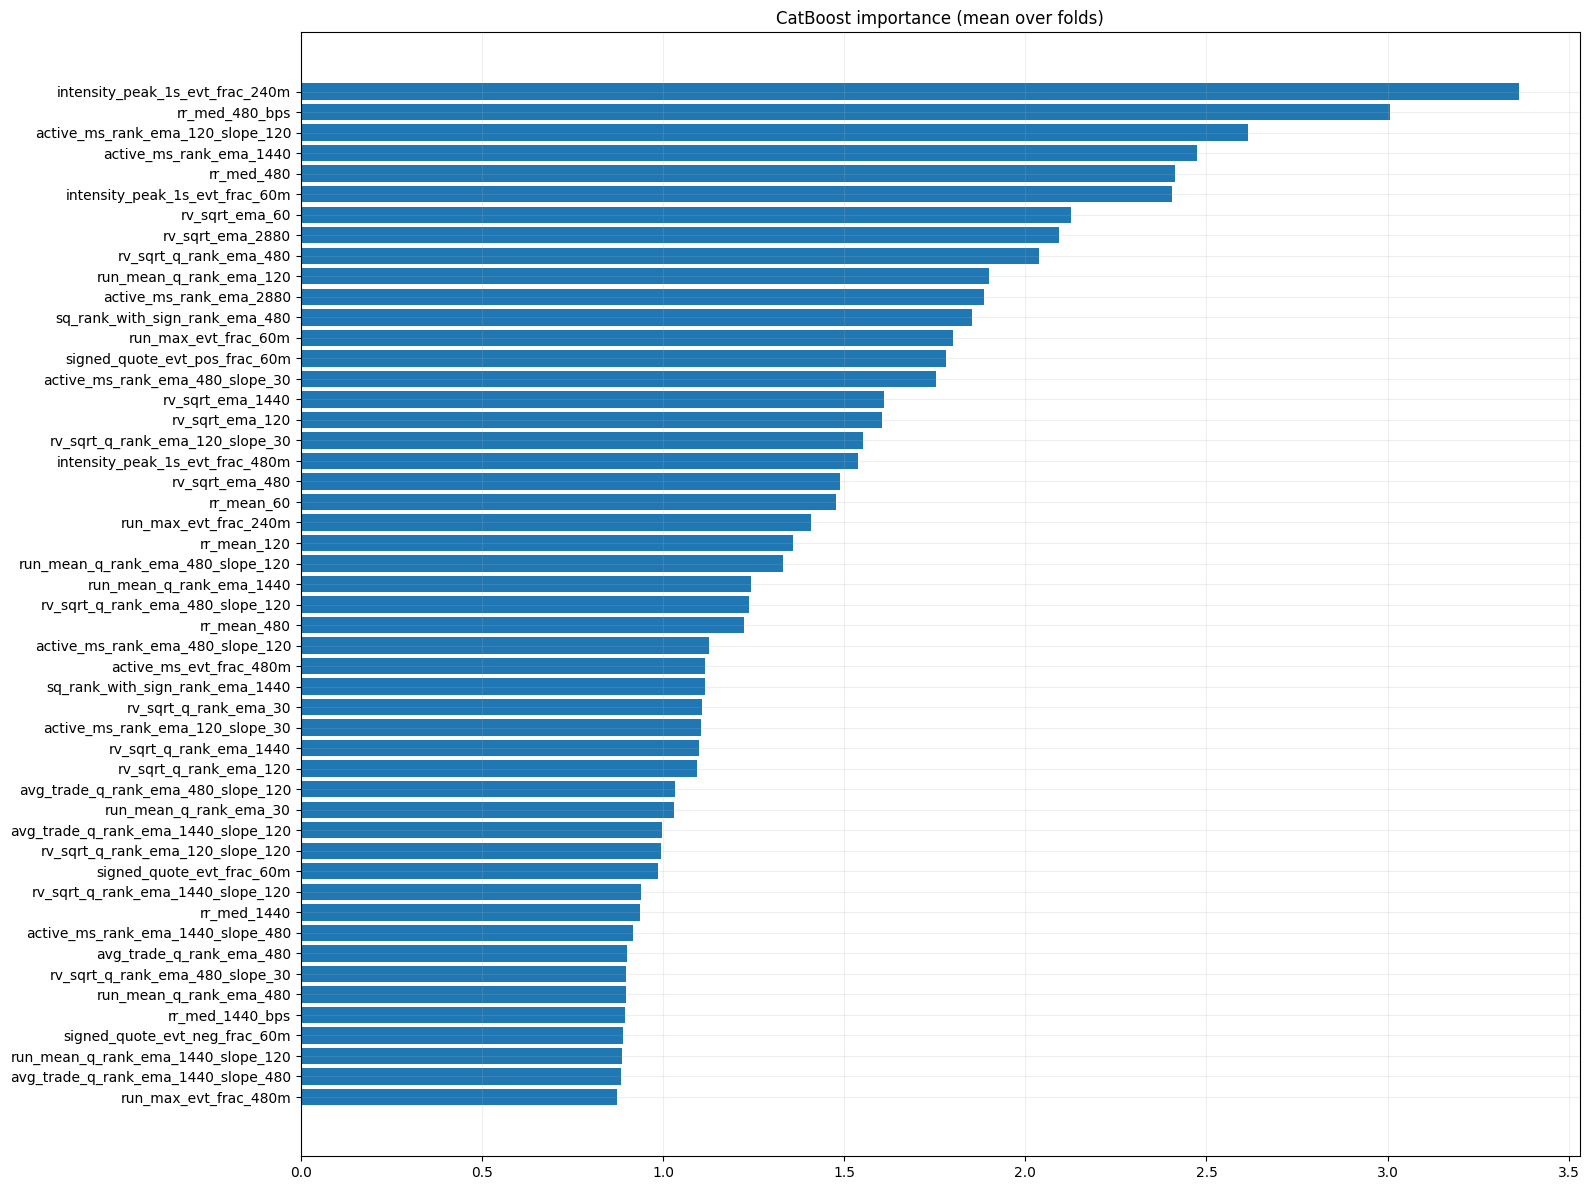

In [ ]:
import matplotlib.pyplot as plt

def plot_top_importance(df_top: pd.DataFrame, value_col="imp_mean", title="Top Feature Importance"):
    d = df_top.copy().iloc[::-1]  # reverse for nice barh
    plt.figure(figsize=(8*2, 6*2))
    plt.barh(d["feature"], d[value_col])
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

plot_top_importance(fi_all.head(50), value_col="imp_mean", title="CatBoost importance (mean over folds)")

In [ ]:
pred["y_pred"] = pred["p"] > 0.5

In [ ]:
pred_pl = pl.from_pandas(
    pred[["t", "p", "y_pred"]]
)

In [ ]:
df2 = df_labeled.join(
    pred_pl,
    on="t",
    how="inner"   # หรือ "left" ถ้าอยากเก็บทุกแถว
)

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df2 = make_binary(df2)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_tb30_compare_strip(
    df: pl.DataFrame,
    i: int,
    *,
    tcol="t",
    close_col="close",
    U_col="_U",
    L_col="_L",
    H=30,
    pad_left=300,
    pad_right=300,
    # truth/pred sources
    y_true_col="y_hit",
    y_pred_col="y_pred",
    p_col="p",
    use_p_as_pred=True,
    p_thr=0.55,
    # display toggles
    show_p=True,
    show_price_band=True,
    # marker sizes
    s_top=18,
    s_strip=18,
    alpha=0.85,
):
    df = df.sort(tcol)
    n = len(df)

    a = max(0, i - pad_left)
    b = min(n, i + H + pad_right)

    # window arrays
    t = df[tcol].to_numpy()[a:b]
    close = np.asarray(df[close_col].to_numpy()[a:b], dtype=float)
    U = np.asarray(df[U_col].to_numpy()[a:b], dtype=float)
    L = np.asarray(df[L_col].to_numpy()[a:b], dtype=float)

    # y_true in window
    y_true = np.asarray(df[y_true_col].to_numpy()[a:b], dtype=float)
    y_true = np.where(np.isfinite(y_true), y_true, 0.0).astype(int)

    # y_pred source
    if use_p_as_pred:
        if p_col not in df.columns:
            raise ValueError(f"p_col='{p_col}' not found in df")
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float)
        p = np.where(np.isfinite(p), p, np.nan)
        y_pred = (p >= p_thr).astype(int)
    else:
        y_pred = np.asarray(df[y_pred_col].to_numpy()[a:b], dtype=float)
        y_pred = np.where(np.isfinite(y_pred), y_pred, 0.0).astype(int)
        # still get p for plotting if available
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float) if (p_col in df.columns) else None
        if p is not None:
            p = np.where(np.isfinite(p), p, np.nan)

    # confusion masks
    true1 = (y_true == 1)
    pred1 = (y_pred == 1)
    tp = true1 & pred1
    fp = (~true1) & pred1
    fn = true1 & (~pred1)
    tn = (~true1) & (~pred1)

    # --- build figure layout ---
    nrows = 3 if (show_p and (p is not None)) else 2
    height_ratios = [4, 1.3, 0.8] if nrows == 3 else [4, 0.9]

    fig, axes = plt.subplots(
        nrows=nrows, ncols=1, figsize=(14, 6 if nrows == 3 else 5),
        sharex=True, gridspec_kw={"height_ratios": height_ratios}
    )
    ax_price = axes[0]
    ax_p = axes[1] if nrows == 3 else None
    ax_strip = axes[2] if nrows == 3 else axes[1]

    # ===== Panel 1: price + bands =====
    ax_price.plot(t, close, label="close")
    ax_price.plot(t, U, linestyle="--", label="U[t]")
    ax_price.plot(t, L, linestyle="--", label="L[t]")

    if show_price_band and (i + H < n):
        ax_price.axvspan(df[tcol][i], df[tcol][i + H], alpha=0.12, label=f"H={H}")
    ax_price.axvline(df[tcol][i], linestyle=":", alpha=0.6)

    # mark TP/FP/FN on price (optional but helpful)
    ax_price.scatter(t[tp], close[tp], s=s_top, c="green", alpha=alpha, label="TP")
    ax_price.scatter(t[fp], close[fp], s=s_top, c="red", alpha=alpha, marker="x", label="FP")
    ax_price.scatter(t[fn], close[fn], s=s_top, c="purple", alpha=alpha, marker="x", label="FN")

    ax_price.grid(alpha=0.2)

    # ===== Panel 2: p line =====
    if ax_p is not None:
        ax_p.plot(t, p, alpha=0.7, label="p")
        ax_p.set_ylim(0, 1)
        ax_p.hlines(p_thr, t[0], t[-1], linestyles="--", alpha=0.6, label=f"p_thr={p_thr}")
        ax_p.grid(alpha=0.2)
        ax_p.legend(loc="upper left")

    # ===== Panel 3: strip (TP/FP/FN/TN) =====
    # Put them on 4 discrete y-levels to avoid overlap
    # y levels: TP=3, FP=2, FN=1, TN=0
    y_strip = np.full(len(t), np.nan, dtype=float)
    y_strip[tp] = 3
    y_strip[fp] = 2
    y_strip[fn] = 1
    y_strip[tn] = 0

    ax_strip.scatter(t[tn], np.zeros(tn.sum()), s=s_strip, c="gray", alpha=0.35, label="TN")
    ax_strip.scatter(t[fn], np.ones(fn.sum()), s=s_strip, c="purple", alpha=alpha, label="FN")
    ax_strip.scatter(t[fp], np.full(fp.sum(), 2.0), s=s_strip, c="red", alpha=alpha, label="FP")
    ax_strip.scatter(t[tp], np.full(tp.sum(), 3.0), s=s_strip, c="green", alpha=alpha, label="TP")

    ax_strip.set_yticks([0, 1, 2, 3])
    ax_strip.set_yticklabels(["TN", "FN", "FP", "TP"])
    ax_strip.grid(alpha=0.2, axis="x")

    # titles + legend
    mode = "p>=thr" if use_p_as_pred else "y_pred col"
    prec = tp.sum() / max(1, (tp.sum() + fp.sum()))
    rec = tp.sum() / max(1, (tp.sum() + fn.sum()))

    ax_price.set_title(
        f"Compare (mode={mode}) | window [{a}:{b}) | center i={i} | "
        f"TP={tp.sum()} FP={fp.sum()} FN={fn.sum()} | precision={prec:.3f} recall={rec:.3f}"
    )
    ax_price.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

    return {
        "a": a, "b": b,
        "tp": int(tp.sum()), "fp": int(fp.sum()), "fn": int(fn.sum()), "tn": int(tn.sum()),
        "precision": float(prec), "recall": float(rec),
        "mode": mode,
    }

In [ ]:
df2.with_row_index().filter(pl.col("p") > 0.9)

index,i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,…,rv_sqrt_evt_frac_60m,rv_sqrt_evt_frac_240m,rv_sqrt_evt_frac_480m,run_max_thr_hi_Lint,run_max_evt,run_max_sev,run_max_evt_frac_60m,run_max_evt_frac_240m,run_max_evt_frac_480m,intensity_peak_1s_thr_hi_Lint,intensity_peak_1s_evt,intensity_peak_1s_sev,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,intensity_peak_1s_evt_frac_480m,realized_range,realized_range_bps,rr_med_120,rr_med_120_bps,rr_med_480,rr_med_480_bps,rr_med_1440,rr_med_1440_bps,rr_mean_30,rr_mean_60,rr_mean_120,rr_mean_480,rr_mean_1440,_rr_base,_U,_L,y_tb30,y_tb30_tie,y_tb30_width_bps,p,y_pred,y_hit
u32,u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,…,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,f64,bool,i8
1,393599,2020-10-01 00:01:00,360.09,360.59,360.04,360.44,1487.61534,536137.756742,243.0,128.0,115.0,236333.478202,299804.27854,360.400799,4.05,-0.118385,0.55,0.001526,360.07,0.000972,0.001027,0.000056,243.31405,101.5,717.0,0.181818,8.0308e-7,0.396694,146,79,67,0.12,-0.1,242,2206.328217,2.91521,…,0.0,0.0,0.0,56.0,0,0.0,0.033333,0.016667,0.008333,89.0,0,0.0,0.016667,0.008333,0.00625,0.55,15.259128,0.265,7.376671,0.25,6.957974,0.25,6.961656,0.288333,0.310333,0.301917,0.273208,0.271431,6.957974,361.813651,359.066349,-1.0,false,76.220785,0.924259,true,1
3,393601,2020-10-01 00:03:00,360.24,360.54,360.18,360.39,608.02127,219109.959618,163.0,77.0,86.0,112526.046504,106583.913114,360.365616,2.716667,0.027119,0.36,0.000999,360.24,0.000416,0.000416,0.0,366.098765,89.5,1207.0,0.12963,4.7505e-7,0.432099,92,50,42,0.11,-0.07,162,1344.232881,1.29001,…,0.0,0.0,0.0,56.0,0,0.0,0.033333,0.016667,0.008333,89.0,0,0.0,0.016667,0.008333,0.00625,0.36,9.989178,0.265,7.376671,0.25,6.957974,0.25,6.961656,0.298333,0.308,0.30275,0.2735,0.271201,6.957974,361.76346,359.01654,-1.0,false,76.220785,0.919122,true,1
12,393610,2020-10-01 00:12:00,359.84,360.29,359.84,360.27,518.58698,186720.37935,166.0,67.0,99.0,87819.351807,98901.027543,360.05605,2.766667,-0.059349,0.45,0.00125,359.86,0.001194,0.001139,-0.000056,352.042424,64.0,1090.0,0.175758,7.5816e-7,0.50303,82,53,29,0.1,-0.12,165,1124.821562,1.38927,…,0.0,0.0,0.0,56.0,0,0.0,0.033333,0.016667,0.008333,89.0,0,0.0,0.016667,0.008333,0.00625,0.45,12.490632,0.28,7.766883,0.25,6.986266,0.25,6.966611,0.370667,0.354667,0.310333,0.277937,0.272049,6.986266,361.648586,358.891414,-1.0,false,76.530713,0.935983,true,1
14,393612,2020-10-01 00:14:00,360.28,360.36,360.19,360.26,291.87235,105163.190696,105.0,18.0,87.0,15551.763127,89611.427568,360.305424,1.75,-0.704236,0.17,0.000472,360.28,-0.000056,-0.000056,0.0,565.365385,181.5,1531.0,0.144231,1.4483e-7,0.615385,40,21,19,0.04,-0.07,104,1001.554197,1.01696,…,0.0,0.0,0.0,56.0,0,0.0,0.033333,0.016667,0.008333,89.0,0,0.0,0.016667,0.008333,0.00625,0.17,4.718814,0.28,7.769362,0.25,6.970994,0.25,6.966611,0.367333,0.355667,0.311917,0.277625,0.271868,6.970994,361.635534,358.884466,-1.0,false,76.363417,0.95387,true,1
15,393613,2020-10-01 00:15:00,360.27,360.63,360.27,360.52,767.14771,276585.526192,247.0,78.0,169.0,129056.46753,147529.058662,360.537511,4.116667,-0.066788,0.36,0.000999,360.26,0.000694,0.000721,0.000028,232.5,36.5,724.0,0.219512,7.5485e-7,0.447154,136,73,63,0.08,-0.09,246,1119.779458,1.00144,…,0.0,0.0,0.0,56.0,1,0.208755,0.05,0.020833,0.010417,89.0,0,0.0,0.016667,0.008333,0.00625,0.36,9.985576,0.28,7.769362,0.25,6.986266,0.25,6.978857,0.374667,0.3585,0.312583,0.278021,0.271986,6.986266,361.899543,359.140457,-1.0,false,76.530713,0.916738,true,1
…,…,…,…,…,…,…,…,…,

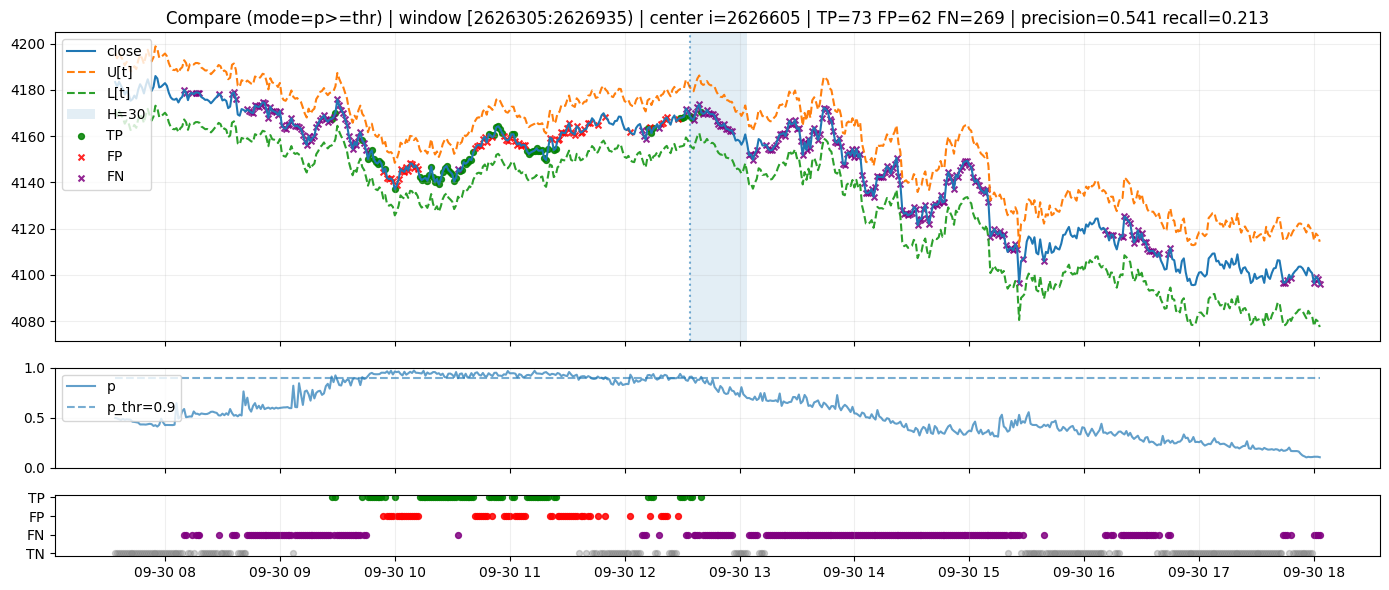

{'a': 2626305,
 'b': 2626935,
 'tp': 73,
 'fp': 62,
 'fn': 269,
 'tn': 226,
 'precision': 0.5407407407407407,
 'recall': 0.2134502923976608,
 'mode': 'p>=thr'}

In [ ]:
plot_tb30_compare_strip(df2, i=2626605, H=30, use_p_as_pred=True, p_thr=0.9)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Core helpers
# -----------------------------
def _confusion_counts(y_true: np.ndarray, y_pred: np.ndarray):
    y_true = y_true.astype(int)
    y_pred = y_pred.astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall    = tp / (tp + fn) if (tp + fn) else np.nan
    fpr       = fp / (fp + tn) if (fp + tn) else np.nan
    tpr       = recall
    acc       = (tp + tn) / (tp + fp + fn + tn) if (tp + fp + fn + tn) else np.nan
    return tp, fp, fn, tn, precision, recall, fpr, tpr, acc

def _logloss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y*np.log(p) + (1-y)*np.log(1-p)).mean())

def _brier(y, p):
    return float(np.mean((p - y) ** 2))

# -----------------------------
# EDA tables
# -----------------------------
def per_fold_metrics(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        yhat = g[y_pred_col].astype(int).values
        p = g[p_col].astype(float).values

        tp, fp, fn, tn, precision, recall, fpr, tpr, acc = _confusion_counts(y, yhat)
        rows.append({
            "fold": fold,
            "n": len(g),
            "base_rate": float(y.mean()),
            "pred_rate": float(yhat.mean()),
            "mean_p": float(np.mean(p)),
            "p_p10": float(np.quantile(p, 0.10)),
            "p_p50": float(np.quantile(p, 0.50)),
            "p_p90": float(np.quantile(p, 0.90)),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": precision, "recall": recall, "fpr": fpr, "acc": acc,
            "logloss": _logloss(y, p),
            "brier": _brier(y, p),
        })
    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

def lift_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
    by_fold: bool = False,
    fold_col="fold",
):
    df = pred[[p_col, y_col] + ([fold_col] if by_fold else [])].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    def _one(g):
        # qcut so each bin has ~equal size
        g = g.copy()
        g["bin"] = pd.qcut(g[p_col], q=n_bins, duplicates="drop")
        out = g.groupby("bin", observed=True).agg(
            n=(y_col, "size"),
            p_mean=(p_col, "mean"),
            y_rate=(y_col, "mean"),
            p_min=(p_col, "min"),
            p_max=(p_col, "max"),
        ).reset_index(drop=True)
        base = float(g[y_col].mean())
        out["lift_vs_base"] = out["y_rate"] / (base + 1e-12)
        # sort from high-p to low-p
        out = out.sort_values("p_mean", ascending=False).reset_index(drop=True)
        return out

    if by_fold:
        res = []
        for f, g in df.groupby(fold_col):
            tmp = _one(g)
            tmp[fold_col] = f
            res.append(tmp)
        return pd.concat(res, ignore_index=True)
    else:
        return _one(df)

def calibration_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
):
    df = pred[[p_col, y_col]].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    df["bin"] = pd.qcut(df[p_col], q=n_bins, duplicates="drop")
    cal = df.groupby("bin", observed=True).agg(
        n=(y_col, "size"),
        p_mean=(p_col, "mean"),
        y_rate=(y_col, "mean"),
        p_min=(p_col, "min"),
        p_max=(p_col, "max"),
    ).reset_index(drop=True)
    cal["gap(y_rate - p_mean)"] = cal["y_rate"] - cal["p_mean"]
    return cal.sort_values("p_mean").reset_index(drop=True)

def error_breakdown(
    pred: pd.DataFrame,
    *,
    y_col="y",
    y_pred_col="y_pred",
    group_cols=("climate_group", "regime_id_confirmed"),
):
    # keep only existing group cols
    group_cols = [c for c in group_cols if c in pred.columns]
    if not group_cols:
        return None

    df = pred.copy()
    y = df[y_col].astype(int).values
    yhat = df[y_pred_col].astype(int).values

    df["_TP"] = ((y == 1) & (yhat == 1)).astype(int)
    df["_FP"] = ((y == 0) & (yhat == 1)).astype(int)
    df["_FN"] = ((y == 1) & (yhat == 0)).astype(int)
    df["_TN"] = ((y == 0) & (yhat == 0)).astype(int)

    out = df.groupby(group_cols, observed=True).agg(
        n=(y_col, "size"),
        base_rate=(y_col, "mean"),
        pred_rate=(y_pred_col, "mean"),
        tp=("_TP", "sum"),
        fp=("_FP", "sum"),
        fn=("_FN", "sum"),
        tn=("_TN", "sum"),
    ).reset_index()

    out["precision"] = out["tp"] / (out["tp"] + out["fp"]).replace(0, np.nan)
    out["recall"]    = out["tp"] / (out["tp"] + out["fn"]).replace(0, np.nan)
    out["fpr"]       = out["fp"] / (out["fp"] + out["tn"]).replace(0, np.nan)
    return out.sort_values(["n"], ascending=False).reset_index(drop=True)

# -----------------------------
# Plots (matplotlib only)
# -----------------------------
def plot_calibration(cal: pd.DataFrame):
    plt.figure(figsize=(6,5))
    plt.plot(cal["p_mean"], cal["y_rate"], marker="o")
    plt.plot([0,1],[0,1], linestyle="--")
    plt.xlabel("mean predicted p")
    plt.ylabel("empirical y=1 rate")
    plt.title("Calibration (Reliability)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_lift(lift: pd.DataFrame, base_rate: float = None):
    plt.figure(figsize=(6,4))
    plt.plot(lift["y_rate"].values, marker="o")
    if base_rate is not None:
        plt.axhline(base_rate, linestyle="--")
    plt.ylabel("y=1 rate")
    plt.title("Lift by p-bin (high→low)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_rolling_p_vs_y(
    pred: pd.DataFrame,
    *,
    t_col="t",
    p_col="p",
    y_col="y",
    window=500,
    min_periods=100,
):
    df = pred[[t_col, p_col, y_col]].copy()
    df[t_col] = pd.to_datetime(df[t_col])
    df = df.sort_values(t_col)
    df["p_roll"] = df[p_col].astype(float).rolling(window, min_periods=min_periods).mean()
    df["y_roll"] = df[y_col].astype(int).rolling(window, min_periods=min_periods).mean()

    plt.figure(figsize=(10,4))
    plt.plot(df[t_col], df["p_roll"], label="rolling mean p")
    plt.plot(df[t_col], df["y_roll"], label="rolling mean y")
    plt.title(f"Rolling mean p vs y (window={window})")
    plt.xlabel("time")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

# -----------------------------
# One-call EDA runner
# -----------------------------
def run_pred_eda(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    t_col="t",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),
    do_plots=True,
):
    # tables
    pf = per_fold_metrics(pred, fold_col=fold_col, y_col=y_col, y_pred_col=y_pred_col, p_col=p_col)
    lift = lift_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins, by_fold=False)
    cal = calibration_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins)
    err = error_breakdown(pred, y_col=y_col, y_pred_col=y_pred_col, group_cols=group_cols)

    if do_plots:
        plot_calibration(cal)
        base = float(pred[y_col].astype(int).mean())
        plot_lift(lift, base_rate=base)
        plot_rolling_p_vs_y(pred, t_col=t_col, p_col=p_col, y_col=y_col)

    return {
        "per_fold": pf,
        "lift": lift,
        "calibration": cal,
        "error_breakdown": err,
    }

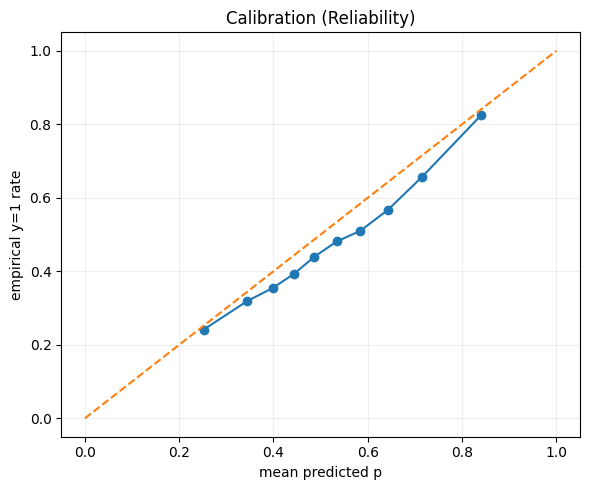

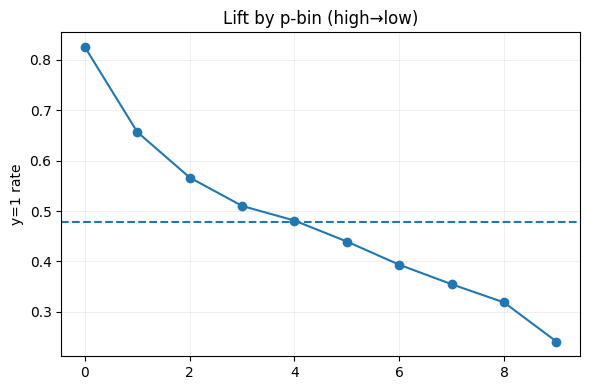

/tmp/ipython-input-462777707.py:208: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


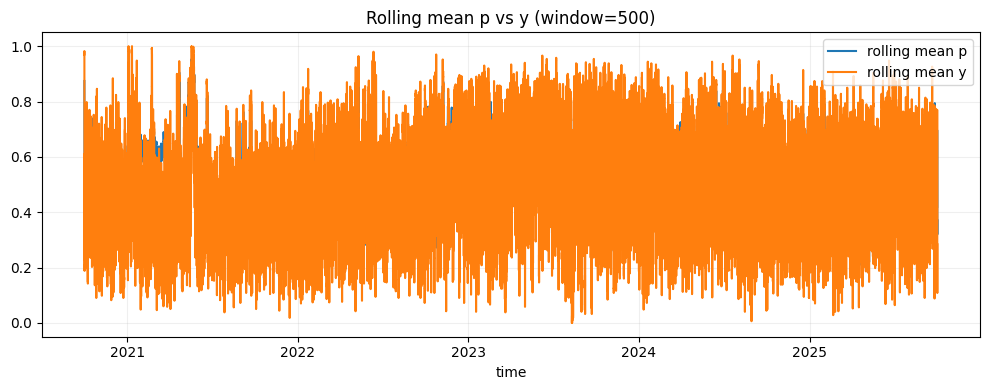

In [ ]:
out = run_pred_eda(
    pred,
    y_col="y",          # ของจริง (hit)
    y_pred_col="y_pred",
    p_col="p",
    fold_col="fold",
    t_col="t",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),  # ถ้ายังไม่ได้ join ก็ปล่อยไว้ได้
    do_plots=True,
)

In [ ]:
import numpy as np
import pandas as pd

def sweep_thresholds_per_fold(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    p_col="p",
    thresholds=None,
):
    if thresholds is None:
        thresholds = np.linspace(0.2, 0.9, 15)

    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        base = y.mean()

        for thr in thresholds:
            yhat = (p >= thr).astype(int)

            tp = np.sum((y == 1) & (yhat == 1))
            fp = np.sum((y == 0) & (yhat == 1))
            fn = np.sum((y == 1) & (yhat == 0))
            tn = np.sum((y == 0) & (yhat == 0))

            precision = tp / (tp + fp) if (tp + fp) else np.nan
            recall    = tp / (tp + fn) if (tp + fn) else np.nan
            trade_rate = yhat.mean()

            rows.append({
                "fold": fold,
                "thr": float(thr),
                "n": len(g),
                "base_rate": float(base),
                "trade_rate": float(trade_rate),
                "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
                "precision": float(precision) if precision==precision else np.nan,
                "recall": float(recall) if recall==recall else np.nan,
            })

    return pd.DataFrame(rows).sort_values(["fold","thr"]).reset_index(drop=True)

In [ ]:
sweep = sweep_thresholds_per_fold(pred)

In [ ]:
def sweep_top(pred, thresholds=(0.50,0.60,0.70,0.80,0.90), fold_col="fold", y_col="y", p_col="p"):
    out = []
    for thr in thresholds:
        rows = sweep_thresholds_per_fold(
            pred,
            fold_col=fold_col,
            y_col=y_col,
            p_col=p_col,
            thresholds=[thr],   # ต้องเป็น list/iterable
        )
        out.append(rows)
    return pd.concat(out, ignore_index=True)

p_sweep = sweep_top(pred, thresholds=(0.50,0.60,0.70,0.80,0.90), p_col="p")

In [ ]:
p_sweep.groupby("thr")[["precision","recall","trade_rate","base_rate"]].mean().reset_index()

,thr,precision,recall,trade_rate,base_rate
0,0.5,0.610089,0.646903,0.520187,0.478771
1,0.6,0.687042,0.441053,0.320551,0.478771
2,0.7,0.783208,0.258932,0.167704,0.478771
3,0.8,0.868566,0.115669,0.066221,0.478771
4,0.9,0.944630,0.038237,0.020550,0.478771


In [ ]:
def pick_thr_by_precision(sweep: pd.DataFrame, target_precision=0.70):
    out = []
    for fold, g in sweep.groupby("fold"):
        gg = g.dropna(subset=["precision"]).copy()
        gg = gg[gg["precision"] >= target_precision]
        if len(gg) == 0:
            # ถ้าไม่มี threshold ไหนถึงเป้า เลือกที่ precision สูงสุด
            best = g.dropna(subset=["precision"]).sort_values(["precision","trade_rate"], ascending=[False,True]).head(1)
        else:
            # ถ้ามีหลายอันถึงเป้า เลือก trade_rate ต่ำสุด (กัน FP/overtrade)
            best = gg.sort_values(["trade_rate","thr"], ascending=[True,True]).head(1)
        out.append(best)

    return pd.concat(out, ignore_index=True).sort_values("fold").reset_index(drop=True)

In [ ]:
weep = sweep_thresholds_per_fold(pred)
thr_by_fold = pick_thr_by_precision(sweep, target_precision=0.70)

In [ ]:
def topq_policy_per_fold(pred: pd.DataFrame, *, fold_col="fold", y_col="y", p_col="p", q=0.10):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        thr = np.quantile(p, 1 - q)
        yhat = (p >= thr).astype(int)

        tp = np.sum((y == 1) & (yhat == 1))
        fp = np.sum((y == 0) & (yhat == 1))
        fn = np.sum((y == 1) & (yhat == 0))
        tn = np.sum((y == 0) & (yhat == 0))

        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall    = tp / (tp + fn) if (tp + fn) else np.nan

        rows.append({
            "fold": fold,
            "q": q,
            "thr": float(thr),
            "n": len(g),
            "base_rate": float(y.mean()),
            "trade_rate": float(yhat.mean()),
            "precision": float(precision) if precision==precision else np.nan,
            "recall": float(recall) if recall==recall else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        })

    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

In [ ]:
def sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20), fold_col="fold", y_col="y", p_col="p"):
    out = []
    for q in qs:
        rows = topq_policy_per_fold(pred, fold_col=fold_col, y_col=y_col, p_col=p_col, q=q)
        rows["q"] = q
        out.append(rows)
    return pd.concat(out, ignore_index=True)

q_sweep = sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20))

In [ ]:
q_sweep.groupby("q")[["precision","recall","trade_rate","base_rate"]].mean().reset_index()

,q,precision,recall,trade_rate,base_rate
0,0.01,0.943237,0.027748,0.014428,0.478771
1,0.02,0.922047,0.045721,0.023924,0.478771
2,0.05,0.875354,0.096041,0.052435,0.478771
3,0.10,0.822997,0.172354,0.100097,0.478771
4,0.20,0.736291,0.314088,0.204492,0.478771


# Predict Intensity (Expected Magnitude)

In [ ]:
def add_future_range_bps_from_hilo(
    df: pl.DataFrame,
    *,
    H: int,
    high_col: str = "high",
    low_col: str = "low",
    ref_price_col: str = "close",   # ใช้ price_t ในส่วนหารเป็น bps
    time_col: str | None = "t",
    out_col: str | None = None,
    add_log1p: bool = True,
) -> pl.DataFrame:
    if out_col is None:
        out_col = f"future_range_{H}m_bps"

    if time_col is not None and time_col in df.columns:
        df = df.sort(time_col)

    w = H + 1
    hi = pl.col(high_col).cast(pl.Float64)
    lo = pl.col(low_col).cast(pl.Float64)
    p0 = pl.col(ref_price_col).cast(pl.Float64)

    fwd_hi = hi.reverse().rolling_max(window_size=w, min_periods=w).reverse()
    fwd_lo = lo.reverse().rolling_min(window_size=w, min_periods=w).reverse()

    range_bps = (fwd_hi - fwd_lo) * 1e4 / p0

    out = df.with_columns(range_bps.alias(out_col))

    if add_log1p:
        out = out.with_columns(
            pl.col(out_col).log1p().alias(f"{out_col}__log1p")
        )
    return out

In [ ]:
df = add_future_range_bps_from_hilo(df, H=30, high_col="high", low_col="low", ref_price_col="close")

/tmp/ipython-input-3757714514.py:23: DeprecationWarning: the argument `min_periods` for `Expr.rolling_max` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  fwd_hi = hi.reverse().rolling_max(window_size=w, min_periods=w).reverse()
/tmp/ipython-input-3757714514.py:24: DeprecationWarning: the argument `min_periods` for `Expr.rolling_min` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  fwd_lo = lo.reverse().rolling_min(window_size=w, min_periods=w).reverse()


In [ ]:
df

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,q_p99,…,rv_sqrt_ema_480,rv_sqrt_ema_1440,rv_sqrt_ema_2880,L_t_right,rv_sqrt_thr_hi_Lint,rv_sqrt_evt,rv_sqrt_sev,rv_sqrt_evt_frac_60m,rv_sqrt_evt_frac_240m,rv_sqrt_evt_frac_480m,run_max_thr_hi_Lint,run_max_evt,run_max_sev,run_max_evt_frac_60m,run_max_evt_frac_240m,run_max_evt_frac_480m,intensity_peak_1s_thr_hi_Lint,intensity_peak_1s_evt,intensity_peak_1s_sev,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,intensity_peak_1s_evt_frac_480m,realized_range,realized_range_bps,rr_med_120,rr_med_120_bps,rr_med_480,rr_med_480_bps,rr_med_1440,rr_med_1440_bps,rr_mean_30,rr_mean_60,rr_mean_120,rr_mean_480,rr_mean_1440,future_range_30m_bps,future_range_30m_bps__log1p
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,0.000002,0.539326,41,16,25,0.06,-0.06,89,437.966496,1.00526,7.70228,19.36258,…,0.001296,0.001296,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.23,17.826694,null,null,null,null,null,null,null,null,null,null,null,39.528755,3.702012
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,390.46987,0.31116,5.0,51.0,…,0.001294,0.001296,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.12,9.300884,null,null,null,null,null,null,null,null,null,null,null,33.328166,3.535966
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,493.747946,0.62237,19.0,19.38736,…,0.001292,0.001295,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.11,8.528454,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,110.443068,0.328,2.0,8.0,…,0.00129,0.001294,0.001295,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.08,6.202512,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,0.000001,0.352941,33,13,20,0.05,-0.04,51,254.03189,0.62262,3.49697,18.84797,…,0.001289,0.001294,0.001295,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.17,13.190565,null,null,null,null,null,null,null,null,null,null,null,28.708876,3.391446
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,297

In [ ]:
df["future_range_30m_bps"].describe()

statistic,value
str,f64
"""count""",3.15365e6
"""null_count""",2830.0
"""mean""",79.961947
"""std""",74.988495
"""min""",0.32451
"""25%""",38.284776
"""50%""",60.822826
"""75%""",97.229388
"""max""",3959.708232


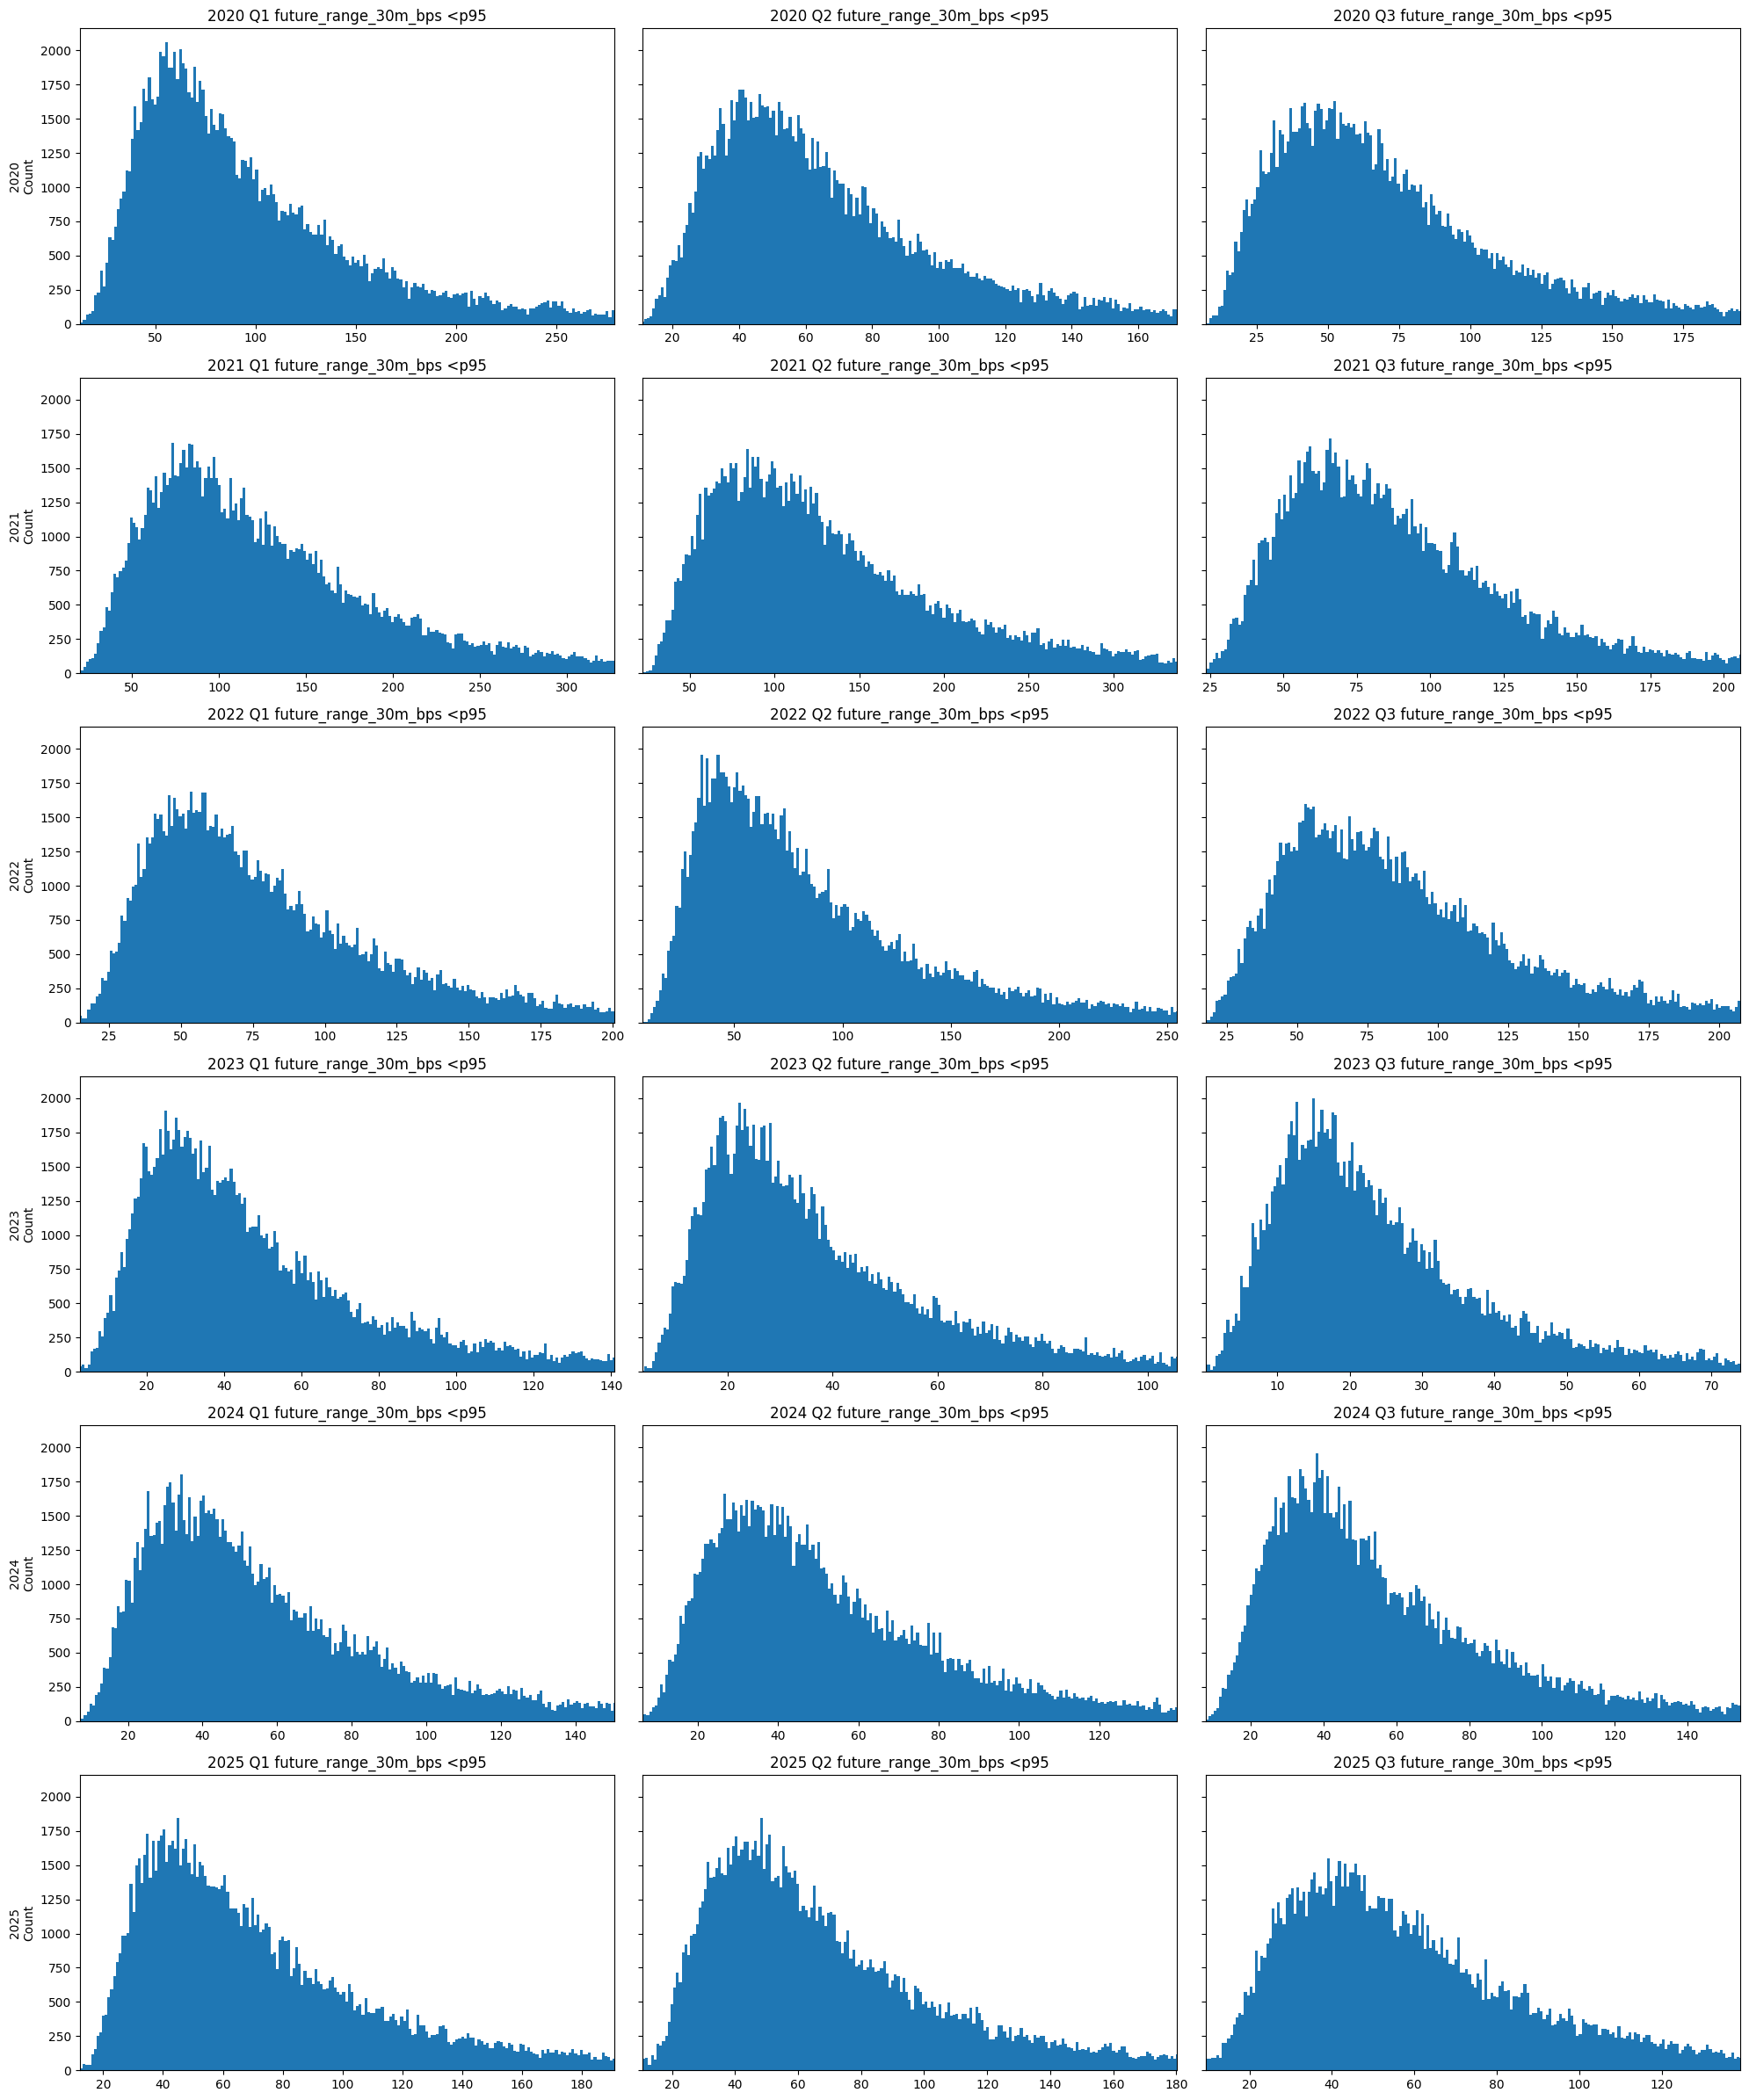

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

years = [2020, 2021, 2022, 2023, 2024, 2025]
quarters = [1, 2, 3]

col = "future_range_30m_bps"

fig, axes = plt.subplots(
    len(years), len(quarters),
    figsize=(20, 4 * len(years)),
    sharey=True,
    sharex=False  # สำคัญ: ให้แต่ละ subplot มีแกน X ของตัวเอง
)

for i, y in enumerate(years):
    for j, q in enumerate(quarters):

        ax = axes[i, j]

        df_yq = df.filter(
            (pl.col("t").dt.year() == y) &
            (pl.col("t").dt.quarter() == q)
        )

        if df_yq.height == 0:
            ax.set_visible(False)
            continue

        # ตัด outlier ด้วย p95 เหมือนเดิม
        p95 = df_yq.select(pl.col(col).quantile(0.95)).item()
        # p05 = df_yq.select(pl.col(col).quantile(0.05)).item()

        s = (
            df_yq
            .filter(pl.col(col) <= p95)
            # .filter(pl.col(col) >= p05)
            .select(col)
            .drop_nulls()
            .to_series()
        )

        if s.len() == 0:
            ax.set_visible(False)
            continue

        data = s.to_numpy()

        # ปรับสเกลแกน X ให้เหมาะกับข้อมูลใน subplot นี้
        # ใช้ q01-q99 เพื่อกันหางสุด ๆ ทำให้ zoom ดู shape ชัดขึ้น
        x_lo = s.quantile(0.01)
        x_hi = s.quantile(0.99)

        # เผื่อกรณีข้อมูลแคบมาก/ค่าคงที่
        if x_lo == x_hi:
            pad = 1e-9 if x_lo == 0 else abs(x_lo) * 0.01
            x_lo -= pad
            x_hi += pad
        else:
            pad = (x_hi - x_lo) * 0.05
            x_lo -= pad
            x_hi += pad

        ax.hist(data, bins=200)
        ax.set_xlim(float(x_lo), float(x_hi))
        ax.set_title(f"{y} Q{q} {col} <p95")

        # ให้ทุก subplot โชว์ตัวเลขแกน X ของตัวเอง
        ax.tick_params(axis="x", labelbottom=True)

    axes[i, 0].set_ylabel(f"{y}\nCount")

plt.tight_layout()
plt.show()

In [ ]:
# drop missing-fill rows + invalid labels
df = df.filter((~pl.col("is_missing_fill")) & pl.col("future_range_30m_bps").is_not_null() & pl.col("future_range_30m_bps").is_finite())

# Drop rows with missing fill or label NaN
df = df.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("future_range_30m_bps").is_not_null())
)

In [ ]:
df = df.with_row_count("i")

/tmp/ipython-input-2155159020.py:1: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df = df.with_row_count("i")


## Train

In [ ]:
model_df = (
    df.select(["t", "future_range_30m_bps"] + FEATURES)
      .filter(
          pl.col("future_range_30m_bps").is_not_null() &
          pl.col("future_range_30m_bps").is_finite()
      )
      .with_columns([
          pl.col("future_range_30m_bps").cast(pl.Float32),
          pl.col("future_range_30m_bps").log1p().alias("y"),
      ])
      .sort("t")
)

In [ ]:
sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3153650 n_features = 117


In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

In [ ]:
folds = make_walkforward_splits(
    df,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,      # test ไม่ซ้อน
    mode="rolling",
    purge_minutes=30,
    embargo_minutes=60,
)

In [ ]:
def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

In [ ]:
X = (
    model_df
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)
)

y = model_df["y"].to_numpy().astype(np.float32)

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.5 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr

fold_results = []
models = {}

for f in folds:
    fold_id = f["fold"]
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostRegressor(
        loss_function="RMSE",
        eval_metric="RMSE",
        depth=6,
        learning_rate=0.05,
        iterations=4000,
        l2_leaf_reg=20,
        subsample=0.8,
        rsm=0.8,
        random_strength=1.0,
        bagging_temperature=1.0,
        random_seed=42,
        verbose=200,
    )

    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    # evaluate on TEST
    pred = model.predict(Xte).astype(np.float32)

    # metrics
    mae = float(mean_absolute_error(yte, pred))
    sp = float(spearmanr(yte, pred).correlation)

    fold_results.append({
        "fold": fold_id,
        "spearman": sp,
        "mae": mae,
        "best_iter": int(model.get_best_iteration() or -1),
        "train_start": f["train_start"],
        "train_end": f["train_end"],
        "test_start": f["test_start"],
        "test_end": f["test_end"],
        "n_train": int(len(tr2_idx)),
        "n_val": int(len(va2_idx)),
        "n_test": int(len(te_idx)),
    })

    models[fold_id] = model

0:	learn: 0.6452412	test: 0.5469730	best: 0.5469730 (0)	total: 137ms	remaining: 9m 8s
200:	learn: 0.4137378	test: 0.4102522	best: 0.4102095 (187)	total: 11s	remaining: 3m 28s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.4102094708
bestIteration = 187

Shrink model to first 188 iterations.
0:	learn: 0.5888800	test: 0.5928414	best: 0.5928414 (0)	total: 55.5ms	remaining: 3m 41s
200:	learn: 0.4130796	test: 0.4100360	best: 0.4065477 (60)	total: 12s	remaining: 3m 46s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.4065477104
bestIteration = 60

Shrink model to first 61 iterations.
0:	learn: 0.6578045	test: 0.5661255	best: 0.5661255 (0)	total: 68.6ms	remaining: 4m 34s
200:	learn: 0.3954648	test: 0.3982595	best: 0.3958889 (149)	total: 11.3s	remaining: 3m 32s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.3958889428
bestIteration = 149

Shrink model to first 150 iterations.
0:	learn: 0.6128583	test: 0.7027554	best: 0.7027554 (0)

In [ ]:
import pandas as pd

res_df = pd.DataFrame(fold_results)
print("\nSummary:")
res_df[["spearman", "mae"]].agg(["mean", "std", "min", "max"])


Summary:


,spearman,mae
mean,0.660653,0.358208
std,0.060794,0.048487
min,0.507237,0.314530
max,0.745075,0.505795


In [ ]:
res_df

,fold,spearman,mae,best_iter,train_start,train_end,test_start,test_end,n_train,n_val,n_test
0,0,0.671781,0.331982,187,2019-12-30 23:00:00,2020-09-30 23:00:00,2020-10-01,2021-01-01,314798,78700,132048
1,1,0.711371,0.336276,60,2020-03-31 23:00:00,2020-12-31 23:00:00,2021-01-01,2021-04-01,316134,79034,129310
2,2,0.711079,0.314530,149,2020-06-30 23:00:00,2021-03-31 23:00:00,2021-04-01,2021-07-01,315070,78768,130566
3,3,0.507237,0.321108,724,2020-09-30 23:00:00,2021-06-30 23:00:00,2021-07-01,2021-10-01,313539,78385,132050
4,4,0.554442,0.350466,126,2020-12-30 23:00:00,2021-09-30 23:00:00,2021-10-01,2022-01-01,314692,78674,132480
5,5,0.633743,0.343248,127,2021-03-31 23:00:00,2021-12-31 23:00:00,2022-01-01,2022-04-01,316076,79020,129600
6,6,0.745075,0.350479,112,2021-06-30 23:00:00,2022-03-31 23:00:00,2022-04-01,2022-07-01,315304,78826,131040
7,7,0.556947,0.345155,118,2021-09-30 23:00:00,2022-06-30 23:00:00,2022-07-01,2022-10-01,314496,78624,132480
8,8,0.669592,0.444434,43,2021-12-30 23:00:00,2022-09-30 23:00:00,2022-10-01,2023-01-01,315648,78912,132480
9,9,0.663631,0.505795,177,2022-03-31 23:00:00,2022-12-31 23:00:00,2023-01-01,2023-04-01,316800,79200,129428


In [ ]:
model_df["future_range_30m_bps"].describe()

statistic,value
str,f64
"""count""",3.15365e6
"""null_count""",0.0
"""mean""",79.961945
"""std""",74.988495
"""min""",0.32451
"""25%""",38.284775
"""50%""",60.822826
"""75%""",97.229385
"""max""",3959.708252


In [ ]:
def topq_lift(y_true, y_hat, q=0.10):
    y_true = np.asarray(y_true)
    y_hat  = np.asarray(y_hat)
    k = max(1, int(len(y_hat) * q))
    idx = np.argpartition(y_hat, -k)[-k:]
    return float(y_true[idx].mean() / y_true.mean())

# ใน loop หลัง pred:
lift10 = topq_lift(yte, pred, q=0.10)

In [ ]:
lift10

1.1544064283370972

In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # t ออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        # รองรับทั้ง classifier และ regressor
        if hasattr(model, "predict_proba"):
            y_hat = model.predict_proba(X[te])[:, 1].astype(np.float32)
        else:
            y_hat = model.predict(X[te]).astype(np.float32)

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te].astype(np.float32),
            "y_hat": y_hat,
            "test_start": f.get("test_start"),
            "test_end": f.get("test_end"),
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

In [ ]:
pred = build_oof_predictions_table(model_df, X, y, folds, models, tcol="t")

In [ ]:
df

i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,…,rv_sqrt_ema_480,rv_sqrt_ema_1440,rv_sqrt_ema_2880,L_t_right,rv_sqrt_thr_hi_Lint,rv_sqrt_evt,rv_sqrt_sev,rv_sqrt_evt_frac_60m,rv_sqrt_evt_frac_240m,rv_sqrt_evt_frac_480m,run_max_thr_hi_Lint,run_max_evt,run_max_sev,run_max_evt_frac_60m,run_max_evt_frac_240m,run_max_evt_frac_480m,intensity_peak_1s_thr_hi_Lint,intensity_peak_1s_evt,intensity_peak_1s_sev,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,intensity_peak_1s_evt_frac_480m,realized_range,realized_range_bps,rr_med_120,rr_med_120_bps,rr_med_480,rr_med_480_bps,rr_med_1440,rr_med_1440_bps,rr_mean_30,rr_mean_60,rr_mean_120,rr_mean_480,rr_mean_1440,future_range_30m_bps,future_range_30m_bps__log1p
u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,…,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,0.000002,0.539326,41,16,25,0.06,-0.06,89,437.966496,1.00526,7.70228,…,0.001296,0.001296,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.23,17.826694,null,null,null,null,null,null,null,null,null,null,null,39.528755,3.702012
1,2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,390.46987,0.31116,5.0,…,0.001294,0.001296,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.12,9.300884,null,null,null,null,null,null,null,null,null,null,null,33.328166,3.535966
2,2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,493.747946,0.62237,19.0,…,0.001292,0.001295,0.001296,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.11,8.528454,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696
3,2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,110.443068,0.328,2.0,…,0.00129,0.001294,0.001295,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.08,6.202512,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696
4,2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,0.000001,0.352941,33,13,20,0.05,-0.04,51,254.03189,0.62262,3.49697,…,0.001289,0.001294,0.001295,60.0,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.17,13.190565,null,null,null,null,null,null,null,null,null,null,null,28.708876,3.391446
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3153645,2025-12-31 23:25:00,2976.02,2976.59,2976.01,2976.59,77.4153,230402.02

In [ ]:
pred

,idx,fold,t,y,y_hat,test_start,test_end
0,393558,0,2020-10-01 00:00:00,4.214402,4.233243,2020-10-01,2021-01-01
1,393559,0,2020-10-01 00:01:00,4.213390,4.203829,2020-10-01,2021-01-01
2,393560,0,2020-10-01 00:02:00,4.213937,4.147799,2020-10-01,2021-01-01
3,393561,0,2020-10-01 00:03:00,4.213527,4.161158,2020-10-01,2021-01-01
4,393562,0,2020-10-01 00:04:00,4.212735,4.324883,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...
2627637,3021195,19,2025-09-30 23:55:00,3.698917,3.687780,2025-07-01,2025-10-01
2627638,3021196,19,2025-09-30 23:56:00,3.742569,3.679727,2025-07-01,2025-10-01
2627639,3021197,19,2025-09-30 23:57:00,3.742517,3.668339,2025-07-01,2025-10-01
2627640,3021198,19,2025-09-30 23:58:00,3.742406,3.664900,2025-07-01,2025-10-01


In [ ]:
xxx = pd.read_csv(str(data_path("Micro Structure Behavior/Intensity_pred.csv")))

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end
0,394560,0,2020-10-01 00:00:00,1,0.749828,2020-10-01,2021-01-01
1,394561,0,2020-10-01 00:01:00,1,0.818157,2020-10-01,2021-01-01
2,394562,0,2020-10-01 00:02:00,1,0.845602,2020-10-01,2021-01-01
3,394563,0,2020-10-01 00:03:00,1,0.862650,2020-10-01,2021-01-01
4,394564,0,2020-10-01 00:04:00,1,0.835907,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...
2629435,3023995,19,2025-09-30 23:55:00,1,0.601783,2025-07-01,2025-10-01
2629436,3023996,19,2025-09-30 23:56:00,1,0.604323,2025-07-01,2025-10-01
2629437,3023997,19,2025-09-30 23:57:00,1,0.654642,2025-07-01,2025-10-01
2629438,3023998,19,2025-09-30 23:58:00,1,0.615889,2025-07-01,2025-10-01


In [ ]:
xxx

,Unnamed: 0,idx,fold,t,y,y_hat,test_start,test_end
0,0,393558,0,2020-10-01 00:00:00,4.214402,4.233243,2020-10-01,2021-01-01
1,1,393559,0,2020-10-01 00:01:00,4.213390,4.203829,2020-10-01,2021-01-01
2,2,393560,0,2020-10-01 00:02:00,4.213937,4.147799,2020-10-01,2021-01-01
3,3,393561,0,2020-10-01 00:03:00,4.213527,4.161158,2020-10-01,2021-01-01
4,4,393562,0,2020-10-01 00:04:00,4.212735,4.324883,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...,...
2627637,2627637,3021195,19,2025-09-30 23:55:00,3.698917,3.687780,2025-07-01,2025-10-01
2627638,2627638,3021196,19,2025-09-30 23:56:00,3.742569,3.679727,2025-07-01,2025-10-01
2627639,2627639,3021197,19,2025-09-30 23:57:00,3.742517,3.668338,2025-07-01,2025-10-01
2627640,2627640,3021198,19,2025-09-30 23:58:00,3.742406,3.664900,2025-07-01,2025-10-01


In [ ]:
pred.to_csv(str(data_path("Micro Structure Behavior/Intensity_pred.csv")))

In [ ]:
import polars as pl
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error

# ให้ df มี idx ตรงกับลำดับแถวที่ใช้สร้าง X,y
# (ถ้าคุณใช้ model_df สร้าง X,y ก็ใช้ model_df ที่นี่แทน df)
df_idx = df.with_row_count("idx")  # idx = 0..n-1

# ดึงเฉพาะ columns ที่อยากใช้ประเมินจาก df (เช่น rv)
RV_COL = "rv_sqrt_ema_480"  # <-- เปลี่ยนให้ตรงของคุณ
extra_cols = ["idx", RV_COL]

df_extra_pd = df_idx.select(extra_cols).to_pandas()

# รวมเข้ากับ pred
pred2 = pred.merge(df_extra_pd, on="idx", how="left")

/tmp/ipython-input-3943387644.py:9: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df_idx = df.with_row_count("idx")  # idx = 0..n-1


In [ ]:
y = pred2["y"].to_numpy(np.float32)
yhat = pred2["y_hat"].to_numpy(np.float32)

sp_all = float(spearmanr(y, yhat).correlation)
mae_all = float(mean_absolute_error(y, yhat))

print("OOF ALL")
print("spearman:", sp_all)
print("mae (bps):", mae_all)

OOF ALL
spearman: 0.7525218234984684
mae (bps): 0.3581414818763733


In [ ]:
rows = []
for fold_id, g in pred2.groupby("fold", sort=True):
    y = g["y"].to_numpy(np.float32)
    yhat = g["y_hat"].to_numpy(np.float32)
    rows.append({
        "fold": fold_id,
        "n": int(len(g)),
        "spearman": float(spearmanr(y, yhat).correlation),
        "mae_bps": float(mean_absolute_error(y, yhat)),
    })

fold_eval = pd.DataFrame(rows).sort_values("fold")
fold_eval

,fold,n,spearman,mae_bps
0,0,132048,0.671781,0.331982
1,1,129310,0.711371,0.336276
2,2,130566,0.711079,0.314530
3,3,132050,0.507237,0.321108
4,4,132480,0.554442,0.350466
5,5,129600,0.633743,0.343248
6,6,131040,0.745075,0.350479
7,7,132480,0.556947,0.345155
8,8,132480,0.669592,0.444434
9,9,129428,0.663631,0.505795


In [ ]:
fold_eval[["spearman","mae_bps"]].agg(["mean","std","min","max"])

,spearman,mae_bps
mean,0.660653,0.358208
std,0.060794,0.048487
min,0.507237,0.314530
max,0.745075,0.505795


In [ ]:
# แบ่ง decile ตาม y_hat
pred2["decile"] = pd.qcut(pred2["y_hat"], 10, labels=False, duplicates="drop")

decile_all = (
    pred2.groupby("decile")
         .agg(n=("y","size"), y_mean=("y","mean"), y_med=("y","median"), y_p90=("y", lambda s: np.quantile(s, 0.9)))
         .reset_index()
         .sort_values("decile")
)

decile_all

,decile,n,y_mean,y_med,y_p90
0,0,262765,3.131466,3.125630,3.818513
1,1,262764,3.543694,3.509673,4.165759
2,2,262764,3.754546,3.721677,4.355125
3,3,262764,3.918845,3.879208,4.517791
4,4,262764,4.061644,4.022509,4.652433
5,5,262764,4.181659,4.143119,4.777030
6,6,262764,4.308355,4.272083,4.895260
7,7,262765,4.461993,4.430861,5.033732
8,8,262763,4.653767,4.620092,5.208194
9,9,262765,5.098687,5.046395,5.764235


## สำรวจคำตอบ

In [ ]:
def decile_table(g):
    g = g.copy()
    g["decile"] = pd.qcut(g["y_hat"], 10, labels=False, duplicates="drop")
    return (
        g.groupby("decile")
         .agg(n=("y","size"), y_mean=("y","mean"))
         .reset_index()
         .assign(fold=g["fold"].iloc[0])
    )

decile_by_fold = pd.concat([decile_table(g) for _, g in pred2.groupby("fold")], ignore_index=True)

# เอาไป pivot ดูง่าย ๆ
decile_pivot = decile_by_fold.pivot(index="decile", columns="fold", values="y_mean")
decile_pivot

fold,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
decile,,,,,,,,,,,,,,,,,,,,
0,3.641026,4.090855,4.220204,4.123450,3.891764,3.837852,3.653799,3.931017,3.177577,2.978079,2.960240,2.318421,3.036689,3.255710,3.188736,3.341655,3.355977,3.598831,3.518715,3.376082
1,3.844764,4.351334,4.374727,4.220336,4.018457,3.960585,3.852235,4.130220,3.332137,3.368355,3.188561,2.656150,3.294616,3.525462,3.464416,3.579611,3.646724,3.770072,3.752470,3.634418
2,3.972555,4.491361,4.526238,4.285087,4.085747,4.051651,3.949388,4.231127,3.466551,3.487944,3.265667,2.870878,3.474336,3.675862,3.610790,3.696956,3.802960,3.882773,3.893489,3.752289
3,4.073040,4.604166,4.634203,4.329333,4.166754,4.138109,4.097704,4.298033,3.600244,3.622569,3.397237,2.994505,3.565638,3.781577,3.737550,3.805323,3.908845,4.009862,3.999360,3.888216
4,4.190393,4.695214,4.742422,4.414407,4.249219,4.248299,4.242687,4.392381,3.707994,3.745744,3.503144,3.088268,3.664309,3.896638,3.841047,3.911078,4.023221,4.101217,4.104964,3.989378
5,4.285347,4.804887,4.827686,4.476206,4.307280,4.342081,4.373542,4.475172,3.800515,3.870400,3.581428,3.190511,3.751626,3.992007,3.942703,3.989038,4.128541,4.220659,4.205149,4.078759
6,4.370387,4.927449,4.939743,4.574216,4.391049,4.425862,4.506784,4.541919,3.966051,3.957328,3.692455,3.288792,3.851833,4.101521,4.050882,4.080570,4.247329,4.360670,4.308325,4.186473
7,4.513773,5.071337,5.055417,4.628240,4.477724,4.558089,4.686117,4.632318,4.111250,4.072829,3.840441,3.450107,3.963143,4.252405,4.187092,4.235088,4.363266,4.515168,4.433653,4.287599
8,4.669846,5.215150,5.287899,4.707448,4.579871,4.727657,4.908431,4.749875,4.350084,4.270068,4.001165,3.638427,4.107810,4.440580,4.339081,4.430085,4.506409,4.682864,4.609321,4.420360


In [ ]:
def topq_lift(y_true, y_hat, q=0.10):
    y_true = np.asarray(y_true, dtype=np.float32)
    y_hat  = np.asarray(y_hat, dtype=np.float32)
    k = max(1, int(len(y_hat) * q))
    idx = np.argpartition(y_hat, -k)[-k:]
    return float(y_true[idx].mean() / y_true.mean())

In [ ]:
lift10_all = topq_lift(pred2["y"], pred2["y_hat"], q=0.10)
lift10_all

1.2401145696640015

In [ ]:
rows = []
for fold_id, g in pred2.groupby("fold", sort=True):
    rows.append({
        "fold": fold_id,
        "lift10": topq_lift(g["y"], g["y_hat"], q=0.10),
        "lift05": topq_lift(g["y"], g["y_hat"], q=0.05),
        "lift20": topq_lift(g["y"], g["y_hat"], q=0.20),
        "n": int(len(g)),
    })
lift_by_fold = pd.DataFrame(rows).sort_values("fold")
lift_by_fold

,fold,lift10,lift05,lift20,n
0,0,1.178555,1.222219,1.137655,132048
1,1,1.173249,1.210941,1.131369,129310
2,2,1.188564,1.225815,1.141047,130566
3,3,1.113491,1.148636,1.082829,132050
4,4,1.130553,1.160229,1.097409,132480
5,5,1.169175,1.202782,1.129750,129600
6,6,1.241722,1.291017,1.182510,131040
7,7,1.118695,1.141741,1.094935,132480
8,8,1.281146,1.360790,1.206451,132480
9,9,1.213172,1.252404,1.168715,129428


In [ ]:
BINS = 5
rows = []

for fold_id, g in pred2.groupby("fold", sort=True):
    gg = g.dropna(subset=[RV_COL]).copy()
    # qcut ภายใน fold
    gg["vol_bin"] = pd.qcut(gg[RV_COL], BINS, labels=False, duplicates="drop")

    for b, gb in gg.groupby("vol_bin", sort=True):
        rows.append({
            "fold": fold_id,
            "vol_bin": int(b),
            "n": int(len(gb)),
            "y_mean": float(gb["y"].mean()),
            "lift10_in_bin": topq_lift(gb["y"], gb["y_hat"], q=0.10),
        })

cond_vol = pd.DataFrame(rows).sort_values(["fold","vol_bin"])
cond_vol

,fold,vol_bin,n,y_mean,lift10_in_bin
0,0,0,26410,3.776459,1.094042
1,0,1,26409,4.046532,1.084303
2,0,2,26410,4.244053,1.081792
3,0,3,26409,4.439848,1.082443
4,0,4,26410,4.782790,1.132745
...,...,...,...,...,...
95,19,0,26496,3.575610,1.137399
96,19,1,26496,3.876926,1.118842
97,19,2,26496,4.025413,1.104846
98,19,3,26496,4.206529,1.106071


In [ ]:
cond_vol_summary = (
    cond_vol.groupby("vol_bin")
            .agg(n=("n","sum"),
                 lift10_mean=("lift10_in_bin","mean"),
                 lift10_std=("lift10_in_bin","std"))
            .reset_index()
            .sort_values("vol_bin")
)

cond_vol_summary

,vol_bin,n,lift10_mean,lift10_std
0,0,525530,1.121649,0.039882
1,1,525527,1.107526,0.027710
2,2,525529,1.104786,0.030825
3,3,525527,1.104108,0.034132
4,4,525529,1.138347,0.032774


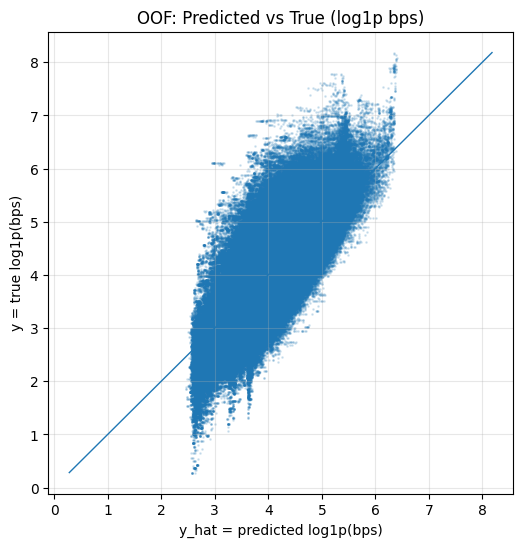

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6,6))
plt.scatter(pred2["y_hat"], pred2["y"], s=1, alpha=0.15)
m = np.nanmin([pred2["y_hat"].min(), pred2["y"].min()])
M = np.nanmax([pred2["y_hat"].max(), pred2["y"].max()])
plt.plot([m, M], [m, M], linewidth=1)  # y=x
plt.xlabel("y_hat = predicted log1p(bps)")
plt.ylabel("y = true log1p(bps)")
plt.title("OOF: Predicted vs True (log1p bps)")
plt.grid(alpha=0.3)
plt.show()

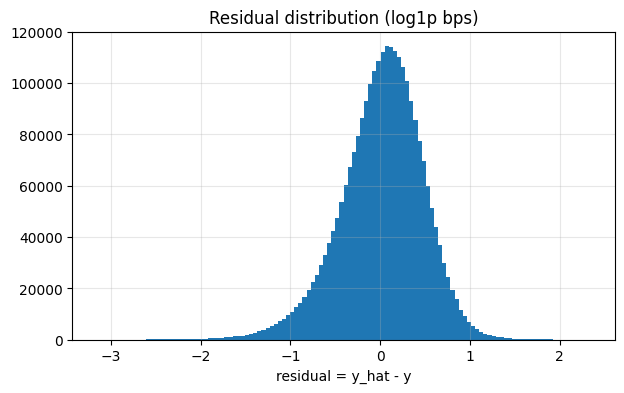

In [ ]:
res = (pred2["y_hat"] - pred2["y"]).to_numpy()
plt.figure(figsize=(7,4))
plt.hist(res, bins=120)
plt.xlabel("residual = y_hat - y")
plt.title("Residual distribution (log1p bps)")
plt.grid(alpha=0.3)
plt.show()

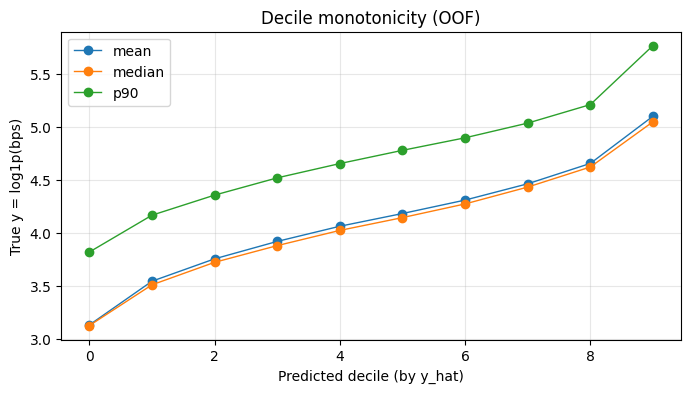

In [ ]:
dec = decile_all.copy()  # จากที่คุณคำนวณไว้: decile, y_mean, y_med, y_p90
plt.figure(figsize=(8,4))
plt.plot(dec["decile"], dec["y_mean"], marker="o", linewidth=1)
plt.plot(dec["decile"], dec["y_med"], marker="o", linewidth=1)
plt.plot(dec["decile"], dec["y_p90"], marker="o", linewidth=1)
plt.xlabel("Predicted decile (by y_hat)")
plt.ylabel("True y = log1p(bps)")
plt.title("Decile monotonicity (OOF)")
plt.grid(alpha=0.3)
plt.legend(["mean", "median", "p90"])
plt.show()

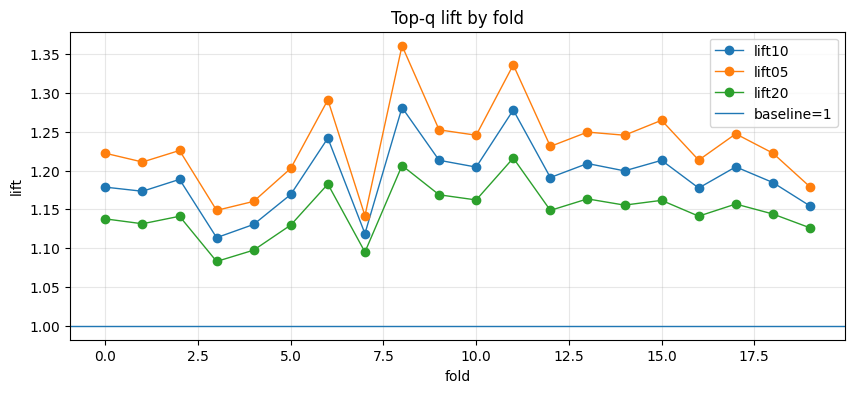

In [ ]:
lift = lift_by_fold.copy()  # fold, lift10, lift05, lift20
plt.figure(figsize=(10,4))
plt.plot(lift["fold"], lift["lift10"], marker="o", linewidth=1)
plt.plot(lift["fold"], lift["lift05"], marker="o", linewidth=1)
plt.plot(lift["fold"], lift["lift20"], marker="o", linewidth=1)
plt.axhline(1.0, linewidth=1)
plt.xlabel("fold")
plt.ylabel("lift")
plt.title("Top-q lift by fold")
plt.grid(alpha=0.3)
plt.legend(["lift10", "lift05", "lift20", "baseline=1"])
plt.show()

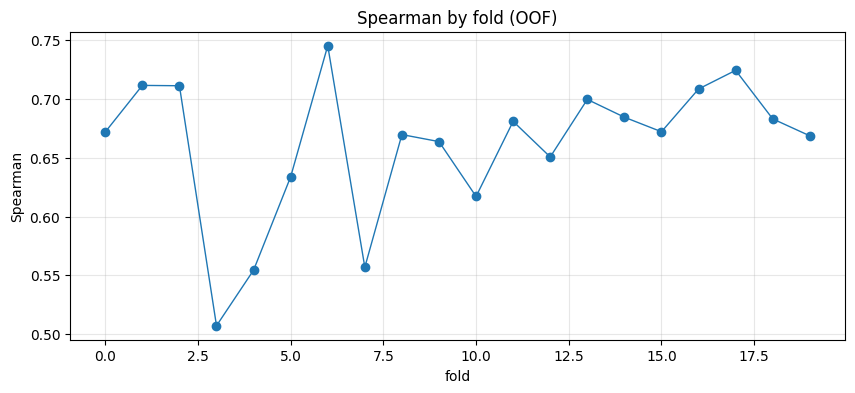

In [ ]:
fe = fold_eval.copy()  # fold, spearman, mae_bps
plt.figure(figsize=(10,4))
plt.plot(fe["fold"], fe["spearman"], marker="o", linewidth=1)
plt.xlabel("fold")
plt.ylabel("Spearman")
plt.title("Spearman by fold (OOF)")
plt.grid(alpha=0.3)
plt.show()

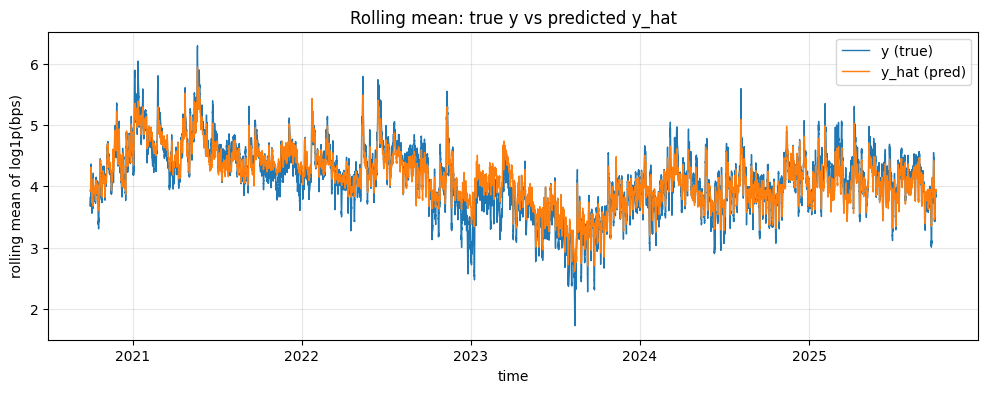

In [ ]:
tmp = pred2.sort_values("t").copy()

# ลดความหนาแน่น: เอา rolling mean 1 วัน (ถ้าเป็น 1 นาที)
# 1 day ~ 1440 นาที
W = 1440

tmp["y_roll"] = tmp["y"].rolling(W, min_periods=W//4).mean()
tmp["yhat_roll"] = tmp["y_hat"].rolling(W, min_periods=W//4).mean()

plt.figure(figsize=(12,4))
plt.plot(tmp["t"], tmp["y_roll"], linewidth=1)
plt.plot(tmp["t"], tmp["yhat_roll"], linewidth=1)
plt.xlabel("time")
plt.ylabel("rolling mean of log1p(bps)")
plt.title("Rolling mean: true y vs predicted y_hat")
plt.grid(alpha=0.3)
plt.legend(["y (true)", "y_hat (pred)"])
plt.show()

# 2 Hat

In [ ]:
pred['t'] = pd.to_datetime(pred['t'], errors='coerce')
xxx['t']  = pd.to_datetime(xxx['t'],  errors='coerce')

m = (
    pred[['fold','t','p']]
    .merge(
        xxx[['fold','t','y_hat']],
        on=['fold','t'],
        how='inner'
    )
    .sort_values(['t'])
    .reset_index(drop=True)
)

In [ ]:
m

,fold,t,p,y_hat
0,0,2020-10-01 00:00:00,0.749828,4.233243
1,0,2020-10-01 00:01:00,0.818157,4.203829
2,0,2020-10-01 00:02:00,0.845602,4.147799
3,0,2020-10-01 00:03:00,0.862650,4.161158
4,0,2020-10-01 00:04:00,0.835907,4.324883
...,...,...,...,...
2627637,19,2025-09-30 23:55:00,0.601783,3.687780
2627638,19,2025-09-30 23:56:00,0.604323,3.679727
2627639,19,2025-09-30 23:57:00,0.654642,3.668338
2627640,19,2025-09-30 23:58:00,0.615889,3.664900


In [ ]:
import numpy as np
import pandas as pd

W = 1440
MINP = 300

m = m.sort_values(['fold','t']).reset_index(drop=True)

# กัน dtype แปลกๆ
m['p'] = pd.to_numeric(m['p'], errors='coerce')
m['y_hat'] = pd.to_numeric(m['y_hat'], errors='coerce')

m['roll_corr'] = np.nan

for f, g in m.groupby('fold', sort=False):
    rc = g['p'].rolling(W, min_periods=MINP).corr(g['y_hat'])
    m.loc[g.index, 'roll_corr'] = rc.to_numpy()

In [ ]:
import matplotlib.pyplot as plt

for f, g in m.groupby('fold'):
    g = g.sort_values('t')

    plt.figure(figsize=(12,4))
    plt.plot(g['t'], g['roll_corr'], lw=1)
    plt.axhline(0, color='gray', ls='--', lw=0.8)

    plt.title(f'Rolling Corr (p vs y_hat) | W=1440 | fold={f}')
    plt.xlabel('time')
    plt.ylabel('corr')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
WIN = '7D'
MINP = 1000

m = m.sort_values(['fold','t'])

m['roll_corr_7d'] = np.nan
for f, g in m.groupby('fold', sort=False):
    gg = g.set_index('t')
    rc = gg['p'].rolling(WIN, min_periods=MINP).corr(gg['y_hat'])
    m.loc[g.index, 'roll_corr_7d'] = rc.to_numpy()

/tmp/ipython-input-2035252751.py:13: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


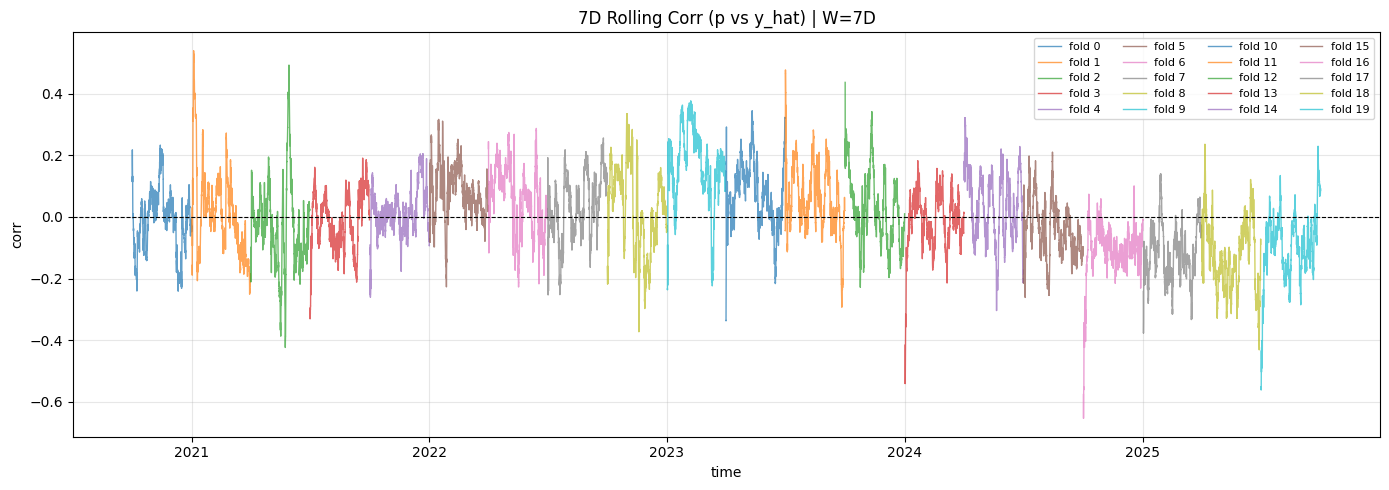

In [ ]:
plt.figure(figsize=(14,5))

for f, g in m.groupby('fold'):
    g = g.sort_values('t')
    plt.plot(g['t'], g['roll_corr_7d'], lw=1, alpha=0.7, label=f'fold {f}')

plt.axhline(0, color='black', ls='--', lw=0.8)
plt.title('7D Rolling Corr (p vs y_hat) | W=7D')
plt.xlabel('time')
plt.ylabel('corr')
plt.grid(alpha=0.3)
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

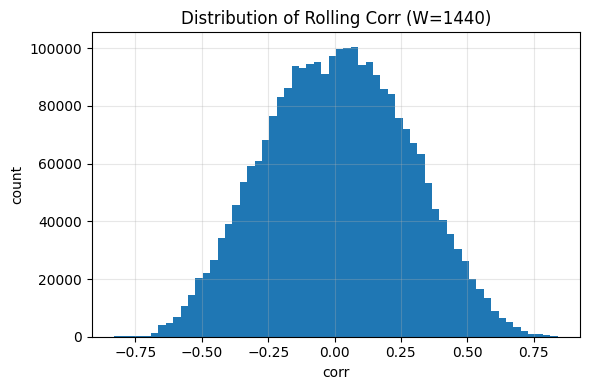

In [ ]:
plt.figure(figsize=(6,4))
m['roll_corr'].dropna().hist(bins=60)
plt.title('Distribution of Rolling Corr (W=1440)')
plt.xlabel('corr')
plt.ylabel('count')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Directional Efficiency

In [ ]:
import polars as pl

def add_tortuosity_roughness(
    df: pl.DataFrame,
    *,
    price_col: str = "close",
    H: int = 30,
    eps: float = 1e-12,
    prefix: str | None = None,
    keep_r: bool = False,
) -> pl.DataFrame:
    """
    Adds forward-looking path metrics over horizon H (minutes/bars):
      - net_H      = |sum r_{t+1..t+H}|
      - path_H     = sum |r_{t+1..t+H}|
      - structure_H = net_H / (path_H + eps)   in [0,1] (trend-like)
      - rough_H     = 1 - structure_H          in [0,1] (chop-like)

    Assumes df is time-sorted and 1 row per bar (e.g., 1 minute).
    """
    tag = prefix or f"H{H}"

    # 1-min log return aligned at time t: r1[t] = log(P_t) - log(P_{t-1})
    df2 = df.with_columns(
        (pl.col(price_col).log().diff()).alias("_r1")
    )

    # forward return stream starting at t: _r1_fwd[t] = _r1[t+1]
    r_fwd = pl.col("_r1").shift(-1)

    # forward rolling sum via reverse trick
    sum_fwd = r_fwd.reverse().rolling_sum(window_size=H, min_periods=H).reverse()
    abs_sum_fwd = r_fwd.abs().reverse().rolling_sum(window_size=H, min_periods=H).reverse()

    # metrics
    df2 = df2.with_columns([
        sum_fwd.abs().alias(f"net_{tag}"),
        abs_sum_fwd.alias(f"path_{tag}"),
    ]).with_columns([
        (pl.col(f"net_{tag}") / (pl.col(f"path_{tag}") + pl.lit(eps)))
            .clip(0.0, 1.0)
            .alias(f"struct_{tag}"),
        (pl.lit(1.0) - pl.col(f"net_{tag}") / (pl.col(f"path_{tag}") + pl.lit(eps)))
            .clip(0.0, 1.0)
            .alias(f"rough_{tag}"),
    ])

    if not keep_r:
        df2 = df2.drop("_r1")

    return df2

In [ ]:
df = add_tortuosity_roughness(
    df,
    price_col="close",
    H=30,
    prefix="H30",
)

/tmp/ipython-input-3650683790.py:32: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  sum_fwd = r_fwd.reverse().rolling_sum(window_size=H, min_periods=H).reverse()
/tmp/ipython-input-3650683790.py:33: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  abs_sum_fwd = r_fwd.abs().reverse().rolling_sum(window_size=H, min_periods=H).reverse()


In [ ]:
df

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,q_p99,…,rv_sqrt_thr_hi_Lint,rv_sqrt_evt,rv_sqrt_sev,rv_sqrt_evt_frac_60m,rv_sqrt_evt_frac_240m,rv_sqrt_evt_frac_480m,run_max_thr_hi_Lint,run_max_evt,run_max_sev,run_max_evt_frac_60m,run_max_evt_frac_240m,run_max_evt_frac_480m,intensity_peak_1s_thr_hi_Lint,intensity_peak_1s_evt,intensity_peak_1s_sev,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,intensity_peak_1s_evt_frac_480m,realized_range,realized_range_bps,rr_med_120,rr_med_120_bps,rr_med_480,rr_med_480_bps,rr_med_1440,rr_med_1440_bps,rr_mean_30,rr_mean_60,rr_mean_120,rr_mean_480,rr_mean_1440,future_range_30m_bps,future_range_30m_bps__log1p,net_H30,path_H30,struct_H30,rough_H30
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,…,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,0.000002,0.539326,41,16,25,0.06,-0.06,89,437.966496,1.00526,7.70228,19.36258,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.23,17.826694,null,null,null,null,null,null,null,null,null,null,null,39.528755,3.702012,0.000155,0.013193,0.011751,0.988249
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,390.46987,0.31116,5.0,51.0,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.12,9.300884,null,null,null,null,null,null,null,null,null,null,null,33.328166,3.535966,0.000853,0.013891,0.061404,0.938596
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,493.747946,0.62237,19.0,19.38736,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.11,8.528454,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696,0.000388,0.013736,0.028228,0.971772
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,110.443068,0.328,2.0,8.0,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.08,6.202512,null,null,null,null,null,null,null,null,null,null,null,28.686618,3.390696,0.000698,0.014046,0.049695,0.950305
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,0.000001,0.352941,33,13,20,0.05,-0.04,51,254.03189,0.62262,3.49697,18.84797,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.17,13.190565,null,null,null,null,null,null,null,null,null,null,null,28.708876,3.391446,0.000543,0.013736,0.039531,0.960469
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971

In [ ]:
df.select(["future_range_30m_bps","future_range_30m_bps__log1p","net_H30","path_H30","struct_H30","rough_H30"]).describe()

statistic,future_range_30m_bps,future_range_30m_bps__log1p,net_H30,path_H30,struct_H30,rough_H30
str,f64,f64,f64,f64,f64,f64
"""count""",3.15365e6,3.15365e6,3.15365e6,3.15365e6,3.15365e6,3.15365e6
"""null_count""",2830.0,2830.0,2830.0,2830.0,2830.0,2830.0
"""mean""",79.961947,4.133343,0.003747,0.020768,0.175804,0.824196
"""std""",74.988495,0.70838,0.004966,0.017057,0.130823,0.130823
"""min""",0.32451,0.281043,0.0,0.000071,0.0,0.013036
"""25%""",38.284776,3.670837,0.000991,0.011206,0.071635,0.746831
"""50%""",60.822826,4.124273,0.002296,0.016924,0.150518,0.849482
"""75%""",97.229388,4.587305,0.004677,0.025367,0.253169,0.928365
"""max""",3959.708232,8.284178,0.295967,0.98212,0.986964,1.0


In [ ]:
import polars as pl

df.select([
    pl.corr("struct_H30", "future_range_30m_bps").alias("corr_struct_range"),
    pl.corr("rough_H30",  "future_range_30m_bps").alias("corr_rough_range"),
    pl.corr("net_H30",    "future_range_30m_bps").alias("corr_net_range"),
    pl.corr("path_H30",   "future_range_30m_bps").alias("corr_path_range"),
])

corr_struct_range,corr_rough_range,corr_net_range,corr_path_range
f64,f64,f64,f64
0.265826,-0.265826,0.840498,0.918381


In [ ]:
q = df.select(pl.col("future_range_30m_bps").quantile(0.)).item()
df_s = df.filter(pl.col("future_range_30m_bps") >= q)

In [ ]:
df_s

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,q_p99,…,rv_sqrt_thr_hi_Lint,rv_sqrt_evt,rv_sqrt_sev,rv_sqrt_evt_frac_60m,rv_sqrt_evt_frac_240m,rv_sqrt_evt_frac_480m,run_max_thr_hi_Lint,run_max_evt,run_max_sev,run_max_evt_frac_60m,run_max_evt_frac_240m,run_max_evt_frac_480m,intensity_peak_1s_thr_hi_Lint,intensity_peak_1s_evt,intensity_peak_1s_sev,intensity_peak_1s_evt_frac_60m,intensity_peak_1s_evt_frac_240m,intensity_peak_1s_evt_frac_480m,realized_range,realized_range_bps,rr_med_120,rr_med_120_bps,rr_med_480,rr_med_480_bps,rr_med_1440,rr_med_1440_bps,rr_mean_30,rr_mean_60,rr_mean_120,rr_mean_480,rr_mean_1440,future_range_30m_bps,future_range_30m_bps__log1p,net_H30,path_H30,struct_H30,rough_H30
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,…,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:52:00,128.76,128.76,128.73,128.74,16.05224,2066.866732,21.0,10.0,11.0,1943.153938,123.712793,128.758773,0.35,0.88029,0.03,0.000233,128.79,-0.000155,-0.000388,-0.000233,2829.5,1471.5,6231.0,0.0,8.4459e-8,0.45,11,5,6,0.01,-0.02,20,98.422225,0.09316,3.0,5.82637,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.03,2.330278,0.09,6.983782,null,null,null,null,0.093667,0.10283,0.10283,null,null,82.336492,4.422887,0.005114,0.012395,0.412558,0.587442
2020-01-01 00:53:00,128.74,128.79,128.7,128.77,53.28377,6861.144287,26.0,10.0,16.0,1280.167721,5580.976566,128.766119,0.433333,-0.626836,0.09,0.000699,128.74,0.000233,0.000233,0.0,2150.76,1660.0,5653.0,0.16,5.3696e-7,0.32,17,10,7,0.04,-0.05,25,263.890165,0.36519,5.0,19.0,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.09,6.989206,0.09,6.984324,null,null,null,null,0.094667,0.102593,0.102593,null,null,82.31731,4.422656,0.006656,0.013938,0.477586,0.522414
2020-01-01 00:54:00,128.77,128.79,128.7,128.73,55.55679,7152.628518,37.0,19.0,18.0,4677.195359,2475.433159,128.744453,0.616667,0.307826,0.09,0.000699,128.77,-0.000311,-0.000311,0.0,1430.944444,355.5,4924.0,0.166667,5.1889e-7,0.361111,23,10,13,0.04,-0.04,36,193.314284,0.36905,3.88171,19.0,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.09,6.991377,0.09,6.984866,null,null,null,null,0.093667,0.102364,0.102364,null,null,82.342888,4.422963,0.007044,0.013704,0.514025,0.485975
2020-01-01 00:55:00,128.73,128.83,128.68,128.78,114.06404,14691.240336,38.0,12.0,26.0,8814.172252,5877.068084,128.798176,0.633333,0.199922,0.15,0.001165,128.73,0.000388,0.000388,0.0,1594.864865,687.0,3864.0,0.135135,8.3857e-7,0.27027,27,14,13,0.05,-0.05,37,386.611588,0.56519,5.0,58.56313,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.15,11.647771,0.09,6.985679,null,null,null,null,0.092333,0.103214,0.103214,null,null,97.064762,4.585628,0.008813,0.015473,0.56959,0.43041
2020-01-01 00:56:00,128.79,128.8,128.76,128.77,6.4326,828.433654,19.0,5.0,14.0,392.513362,435.920292,128.786751,0.316667,-0.052396,0.04,0.000311,128.78,-0.000155,-0.000078,0.000078,2850.777778,1987.0,6219.0,0.055556,1.4472e-7,0.666667,6,3,3,0.02,-0.04,18,43.601771,0.16309,0.66249,1.56447,…,null,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,0.0,null,null,null,0.04,3.106314,0.09,6.984866,null,null,null,null,0.086333,0.102105,0.102105,null,null,103.284927,4.647127,0.008737,0.015549,0.561889,0.438111
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,

In [ ]:
def decile_table(df_in: pl.DataFrame, score_col: str, y_cols: list[str], n=10):
    return (
        df_in
        .with_columns(
            (pl.col(score_col).rank(method="average") / pl.len()).alias("_u")
        )
        .with_columns(
            (pl.col("_u") * n).floor().cast(pl.Int32).clip(0, n-1).alias("decile")
        )
        .group_by("decile")
        .agg(
            pl.len().alias("n"),
            *[pl.col(c).mean().alias(f"{c}_mean") for c in y_cols],
            *[pl.col(c).median().alias(f"{c}_med") for c in y_cols],
        )
        .sort("decile")
    )

dec = decile_table(
    df.drop_nulls(["struct_H30","rough_H30","future_range_30m_bps"]),
    "struct_H30",
    ["struct_H30","rough_H30","future_range_30m_bps","net_H30","path_H30"]
)
dec

decile,n,struct_H30_mean,rough_H30_mean,future_range_30m_bps_mean,net_H30_mean,path_H30_mean,struct_H30_med,rough_H30_med,future_range_30m_bps_med,net_H30_med,path_H30_med
i32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,315365,0.014126,0.985874,61.960142,0.000284,0.020066,0.014141,0.985859,49.161226,0.000208,0.016501
1,315365,0.042608,0.957392,62.890177,0.000857,0.020101,0.042607,0.957393,50.051079,0.000693,0.016592
2,315364,0.071682,0.928318,64.732143,0.001444,0.020143,0.071635,0.928365,51.360751,0.001181,0.016609
3,315366,0.101842,0.898158,67.39612,0.002067,0.020291,0.101806,0.898194,53.265912,0.001685,0.01663
4,315365,0.133773,0.866227,70.757766,0.00273,0.0204,0.133658,0.866342,55.796831,0.002224,0.016691
5,315364,0.168412,0.831588,75.12216,0.003468,0.020593,0.168288,0.831712,59.349164,0.002825,0.016815
6,315365,0.207301,0.792699,80.583423,0.004308,0.020781,0.206975,0.793025,63.784475,0.003502,0.016921
7,315366,0.253783,0.746217,88.080092,0.005356,0.021098,0.253169,0.746831,69.836132,0.004342,0.017148
8,315364,0.316197,0.683803,99.942128,0.006843,0.021629,0.314542,0.685458,79.049886,0.005496,0.017438


In [ ]:
ins_pred = pd.read_csv(str(data_path("Micro Structure Behavior/Intensity_pred.csv")))

In [ ]:
ins_pred["fr_30m_bps_log1p_pred"] = ins_pred["y_hat"]

In [ ]:
ins_pred = pl.DataFrame(ins_pred)

In [ ]:
ins_pred = ins_pred.with_columns(
    pl.col("t").str.to_datetime(time_unit="ms")
)

In [ ]:
ins_pred

Unnamed: 0,idx,fold,t,y,y_hat,test_start,test_end,fr_30m_bps_log1p_pred
i64,i64,i64,datetime[ms],f64,f64,str,str,f64
0,393558,0,2020-10-01 00:00:00,4.214402,4.233243,"""2020-10-01""","""2021-01-01""",4.233243
1,393559,0,2020-10-01 00:01:00,4.2133904,4.203829,"""2020-10-01""","""2021-01-01""",4.203829
2,393560,0,2020-10-01 00:02:00,4.2139373,4.1477985,"""2020-10-01""","""2021-01-01""",4.1477985
3,393561,0,2020-10-01 00:03:00,4.2135267,4.161158,"""2020-10-01""","""2021-01-01""",4.161158
4,393562,0,2020-10-01 00:04:00,4.2127347,4.3248825,"""2020-10-01""","""2021-01-01""",4.3248825
…,…,…,…,…,…,…,…,…
2627637,3021195,19,2025-09-30 23:55:00,3.698917,3.6877797,"""2025-07-01""","""2025-10-01""",3.6877797
2627638,3021196,19,2025-09-30 23:56:00,3.7425687,3.6797273,"""2025-07-01""","""2025-10-01""",3.6797273
2627639,3021197,19,2025-09-30 23:57:00,3.742517,3.6683385,"""2025-07-01""","""2025-10-01""",3.6683385


In [ ]:
df = df.join(ins_pred.select(["t","fr_30m_bps_log1p_pred"]), on="t",how="left")

## Train

In [ ]:
# model_df = (
#     df.select(["t", "struct_H30"] + FEATURES + ["fr_30m_bps_log1p_pred"] + [""])
#       .filter(
#           pl.col("struct_H30").is_not_null() &
#           pl.col("struct_H30").is_finite()
#       )
#       .with_columns([
#           pl.col("struct_H30").cast(pl.Float32),
#           pl.col("struct_H30").log1p().alias("y"),
#       ])
#       .sort("t")
# )

In [ ]:
# import polars as pl

# RANGE_COL = "fr_30m_bps_log1p_pred"  # <-- เปลี่ยนเป็นชื่อจริงของคุณ
# q60 = (
#     df.select(pl.col(RANGE_COL).quantile(0.50).alias("q60"))
#       .item()
# )

# model_df_q60 = (
#     model_df
#     .filter(pl.col(RANGE_COL) >= q60)
# )

# print("q60 =", q60, "rows =", model_df_q60.height)

q60 = 4.1300035 rows = 1313821


In [ ]:
import polars as pl
import numpy as np

RANGE_COL = "fr_30m_bps_log1p_pred"
STRUCT_COL = "struct_H30"
GATE_Q = 0.0          # จะใช้ 0.50 ก็ได้
LOW_Q  = 0.20          # chop-like
HIGH_Q = 0.80          # trend-like

model_df = (
    df.select(["t", STRUCT_COL] + FEATURES + [RANGE_COL])
      .filter(pl.col(STRUCT_COL).is_not_null() & pl.col(STRUCT_COL).is_finite())
      .with_columns(pl.col(STRUCT_COL).cast(pl.Float32))
      .sort("t")
)

# gate ด้วย predicted intensity (production friendly)
# gate_thr = model_df.select(pl.col(RANGE_COL).quantile(GATE_Q)).item()
# df_g = model_df.filter(pl.col(RANGE_COL) >= gate_thr)
df_g = model_df

# ทำ trimmed label ด้วย quantile ของ struct ภายใน gated set
q_lo = df_g.select(pl.col(STRUCT_COL).quantile(LOW_Q)).item()
q_hi = df_g.select(pl.col(STRUCT_COL).quantile(HIGH_Q)).item()

df_cls = (
    df_g
    .with_columns(
        pl.when(pl.col(STRUCT_COL) <= q_hi).then(0)
         .when(pl.col(STRUCT_COL) >= q_hi).then(1)
         .otherwise(None)
         .cast(pl.Int8)
         .alias("y_cls")
    )
    .filter(pl.col("y_cls").is_not_null())
)

print("gate_thr:", gate_thr, "q_lo:", q_lo, "q_hi:", q_hi, "rows:", df_cls.height)

gate_thr: 2.4671795 q_lo: 0.05700021609663963 q_hi: 0.28111281991004944 rows: 3153650


In [ ]:
# sanity_check_time(model_df_q60, "t")
# print("n(model_df) =", model_df_q60.height, "n_features =", len(FEATURES))

n(model_df) = 1313821 n_features = 117


In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

In [ ]:
folds = make_walkforward_splits(
    df_cls,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,      # test ไม่ซ้อน
    mode="rolling",
    purge_minutes=30,
    embargo_minutes=60,
)

In [ ]:
def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

In [ ]:
X = (
    df_cls
    .select(FEATURES +["fr_30m_bps_log1p_pred"])
    .to_numpy()
    .astype(np.float32)
)

y = df_cls["y_cls"].to_numpy().astype(np.float32)

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.5 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

def topq_precision(y_true, p_hat, q=0.10):
    y_true = np.asarray(y_true)
    p_hat  = np.asarray(p_hat)
    k = max(1, int(len(p_hat) * q))
    idx = np.argpartition(p_hat, -k)[-k:]
    return float(y_true[idx].mean())

fold_results = []
oof_p = np.full(len(y), np.nan, dtype=np.float32)

for f in folds:
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        depth=6,
        learning_rate=0.05,
        iterations=4000,
        l2_leaf_reg=20,
        subsample=0.8,
        rsm=0.8,
        random_strength=1.0,
        bagging_temperature=1.0,
        random_seed=42,
        verbose=200,
        auto_class_weights="Balanced",  # เพราะเราเลือก tail ทั้งสองฝั่ง จำนวนอาจไม่เท่ากัน
    )

    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    p = model.predict_proba(Xte)[:, 1].astype(np.float32)
    oof_p[te_idx] = p

    auc = float(roc_auc_score(yte, p)) if len(np.unique(yte)) == 2 else np.nan
    ap  = float(average_precision_score(yte, p)) if len(np.unique(yte)) == 2 else np.nan
    p10 = topq_precision(yte, p, q=0.10)
    p05 = topq_precision(yte, p, q=0.05)

    fold_results.append({
        "fold": f["fold"],
        "auc": auc,
        "ap": ap,
        "p@10%": p10,
        "p@5%": p05,
        "base_rate": float(np.mean(yte)),
        "best_iter": int(model.get_best_iteration() or -1),
        "n_test": int(len(te_idx)),
        "test_start": f["test_start"],
        "test_end": f["test_end"],
    })

0:	test: 0.5137999	best: 0.5137999 (0)	total: 95.7ms	remaining: 6m 22s
200:	test: 0.5222239	best: 0.5339547 (23)	total: 14.6s	remaining: 4m 35s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.533954742
bestIteration = 23

Shrink model to first 24 iterations.
0:	test: 0.5103034	best: 0.5103034 (0)	total: 72.7ms	remaining: 4m 50s
200:	test: 0.5307438	best: 0.5426736 (28)	total: 14.4s	remaining: 4m 31s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.5426736363
bestIteration = 28

Shrink model to first 29 iterations.
0:	test: 0.5239371	best: 0.5239371 (0)	total: 84.8ms	remaining: 5m 38s
200:	test: 0.5308285	best: 0.5313331 (190)	total: 16.2s	remaining: 5m 6s
400:	test: 0.5400155	best: 0.5401616 (394)	total: 31.6s	remaining: 4m 43s
600:	test: 0.5411734	best: 0.5431062 (554)	total: 45.3s	remaining: 4m 16s
800:	test: 0.5454180	best: 0.5454180 (800)	total: 59.5s	remaining: 3m 57s
1000:	test: 0.5436500	best: 0.5467863 (905)	total: 1m 13s	remaining: 3m 4

In [ ]:
# OOF summary
mask = np.isfinite(oof_p)
auc_oof = float(roc_auc_score(y[mask], oof_p[mask]))
ap_oof  = float(average_precision_score(y[mask], oof_p[mask]))
print("OOF AUC:", auc_oof, "OOF AP:", ap_oof)
pl.DataFrame(fold_results)

OOF AUC: 0.5220997816223533 OOF AP: 0.21376444860843918


fold,auc,ap,p@10%,p@5%,base_rate,best_iter,n_test,test_start,test_end
i64,f64,f64,f64,f64,f64,i64,i64,datetime[μs],datetime[μs]
0,0.536592,0.21845,0.241972,0.262345,0.192619,23,132048,2020-10-01 00:00:00,2021-01-01 00:00:00
1,0.534122,0.198063,0.219086,0.23635,0.17919,28,129310,2021-01-01 00:00:00,2021-04-01 00:00:00
2,0.512281,0.203877,0.21875,0.220588,0.195633,905,130566,2021-04-01 00:00:00,2021-07-01 00:00:00
3,0.52868,0.195577,0.203256,0.218722,0.179152,33,132050,2021-07-01 00:00:00,2021-10-01 00:00:00
4,0.518232,0.205076,0.20237,0.199577,0.199517,34,132480,2021-10-01 00:00:00,2022-01-01 00:00:00
…,…,…,…,…,…,…,…,…,…
15,0.501006,0.195924,0.209239,0.221165,0.18941,157,132480,2024-07-01 00:00:00,2024-10-01 00:00:00
16,0.481731,0.19188,0.188859,0.178744,0.199336,72,132480,2024-10-01 00:00:00,2025-01-01 00:00:00
17,0.487582,0.188522,0.180787,0.179784,0.194313,255,129600,2025-01-01 00:00:00,2025-04-01 00:00:00


In [ ]:
# from catboost import CatBoostRegressor
# from sklearn.metrics import mean_absolute_error
# from scipy.stats import spearmanr

# fold_results = []
# models = {}

# for f in folds:
#     fold_id = f["fold"]
#     tr_idx = f["train_idx"]
#     te_idx = f["test_idx"]

#     tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

#     Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
#     Xva2, yva2 = X[va2_idx], y[va2_idx]
#     Xte,  yte  = X[te_idx],  y[te_idx]

#     model = CatBoostRegressor(
#         loss_function="MAE",
#         eval_metric="MAE",
#         depth=6,
#         learning_rate=0.05,
#         iterations=4000,
#         l2_leaf_reg=20,
#         subsample=0.8,
#         rsm=0.8,
#         random_strength=1.0,
#         bagging_temperature=1.0,
#         random_seed=42,
#         verbose=200,
#     )

#     model.fit(
#         Xtr2, ytr2,
#         eval_set=(Xva2, yva2),
#         use_best_model=True,
#         early_stopping_rounds=200,
#     )

#     # evaluate on TEST
#     pred = model.predict(Xte).astype(np.float32)

#     # metrics
#     mae = float(mean_absolute_error(yte, pred))
#     sp = float(spearmanr(yte, pred).correlation)

#     fold_results.append({
#         "fold": fold_id,
#         "spearman": sp,
#         "mae": mae,
#         "best_iter": int(model.get_best_iteration() or -1),
#         "train_start": f["train_start"],
#         "train_end": f["train_end"],
#         "test_start": f["test_start"],
#         "test_end": f["test_end"],
#         "n_train": int(len(tr2_idx)),
#         "n_val": int(len(va2_idx)),
#         "n_test": int(len(te_idx)),
#     })

#     models[fold_id] = model

0:	learn: 0.0833251	test: 0.0875043	best: 0.0875043 (0)	total: 64.8ms	remaining: 4m 19s
200:	learn: 0.0799840	test: 0.0873992	best: 0.0872554 (29)	total: 11.6s	remaining: 3m 38s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.08725542712
bestIteration = 29

Shrink model to first 30 iterations.
0:	learn: 0.0840151	test: 0.0841313	best: 0.0841313 (0)	total: 64.4ms	remaining: 4m 17s
200:	learn: 0.0806940	test: 0.0844369	best: 0.0839431 (31)	total: 12.4s	remaining: 3m 54s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.08394309346
bestIteration = 31

Shrink model to first 32 iterations.
0:	learn: 0.0846946	test: 0.0863959	best: 0.0863959 (0)	total: 61.8ms	remaining: 4m 7s
200:	learn: 0.0814706	test: 0.0865924	best: 0.0862966 (19)	total: 12.5s	remaining: 3m 56s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.08629664475
bestIteration = 19

Shrink model to first 20 iterations.
0:	learn: 0.0852611	test: 0.0894831	best: 0.0894831 (

In [ ]:
import pandas as pd

res_df = pd.DataFrame(fold_results)
print("\nSummary:")
res_df[["spearman", "mae"]].agg(["mean", "std", "min", "max"])


Summary:


,spearman,mae
mean,0.005417,0.085248
std,0.017411,0.002150
min,-0.027380,0.081925
max,0.043854,0.089358


In [ ]:
model_df["future_range_30m_bps"].describe()

statistic,value
str,f64
"""count""",3.15365e6
"""null_count""",0.0
"""mean""",79.961945
"""std""",74.988495
"""min""",0.32451
"""25%""",38.284775
"""50%""",60.822826
"""75%""",97.229385
"""max""",3959.708252


In [ ]:
pred

In [ ]:
def topq_lift(y_true, y_hat, q=0.10):
    y_true = np.asarray(y_true)
    y_hat  = np.asarray(y_hat)
    k = max(1, int(len(y_hat) * q))
    idx = np.argpartition(y_hat, -k)[-k:]
    return float(y_true[idx].mean() / y_true.mean())

# ใน loop หลัง pred:
lift10 = topq_lift(yte, pred, q=0.10)

ValueError: kth(=-262937) out of bounds (7)

In [ ]:
lift10

1.0073628425598145

In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # t ออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        # รองรับทั้ง classifier และ regressor
        if hasattr(model, "predict_proba"):
            y_hat = model.predict_proba(X[te])[:, 1].astype(np.float32)
        else:
            y_hat = model.predict(X[te]).astype(np.float32)

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te].astype(np.float32),
            "y_hat": y_hat,
            "test_start": f.get("test_start"),
            "test_end": f.get("test_end"),
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

In [ ]:
pred = build_oof_predictions_table(model_df, X, y, folds, models, tcol="t")

In [ ]:
pred

,idx,fold,t,y,y_hat,test_start,test_end
0,394560,0,2020-10-01 16:42:00,0.004800,0.125994,2020-10-01,2021-01-01
1,394561,0,2020-10-01 16:43:00,0.041881,0.125878,2020-10-01,2021-01-01
2,394562,0,2020-10-01 16:44:00,0.070447,0.122418,2020-10-01,2021-01-01
3,394563,0,2020-10-01 16:45:00,0.002169,0.123392,2020-10-01,2021-01-01
4,394564,0,2020-10-01 16:46:00,0.114038,0.123392,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...
2629435,3023995,19,2025-10-02 22:35:00,0.073889,0.140436,2025-07-01,2025-10-01
2629436,3023996,19,2025-10-02 22:36:00,0.035500,0.140436,2025-07-01,2025-10-01
2629437,3023997,19,2025-10-02 22:37:00,0.088869,0.140436,2025-07-01,2025-10-01
2629438,3023998,19,2025-10-02 22:38:00,0.080733,0.140784,2025-07-01,2025-10-01


In [ ]:
# xxx = pd.read_csv("/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/Intensity_pred.csv")

In [ ]:
# pred.to_csv("/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/Intensity_pred.csv")

In [ ]:
import polars as pl
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error

# ให้ df มี idx ตรงกับลำดับแถวที่ใช้สร้าง X,y
# (ถ้าคุณใช้ model_df สร้าง X,y ก็ใช้ model_df ที่นี่แทน df)
df_idx = df.with_row_count("idx")  # idx = 0..n-1

# ดึงเฉพาะ columns ที่อยากใช้ประเมินจาก df (เช่น rv)
RV_COL = "rv_sqrt_ema_480"  # <-- เปลี่ยนให้ตรงของคุณ
extra_cols = ["idx", RV_COL]

df_extra_pd = df_idx.select(extra_cols).to_pandas()

# รวมเข้ากับ pred
pred2 = pred.merge(df_extra_pd, on="idx", how="left")

/tmp/ipython-input-3943387644.py:9: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df_idx = df.with_row_count("idx")  # idx = 0..n-1


In [ ]:
y = pred2["y"].to_numpy(np.float32)
yhat = pred2["y_hat"].to_numpy(np.float32)

sp_all = float(spearmanr(y, yhat).correlation)
mae_all = float(mean_absolute_error(y, yhat))

print("OOF ALL")
print("spearman:", sp_all)
print("mae:", mae_all)

OOF ALL
spearman: 0.03413443366941484
mae: 0.08662218600511551


In [ ]:
rows = []
for fold_id, g in pred2.groupby("fold", sort=True):
    y = g["y"].to_numpy(np.float32)
    yhat = g["y_hat"].to_numpy(np.float32)
    rows.append({
        "fold": fold_id,
        "n": int(len(g)),
        "spearman": float(spearmanr(y, yhat).correlation),
        "mae_bps": float(mean_absolute_error(y, yhat)),
    })

fold_eval = pd.DataFrame(rows).sort_values("fold")
fold_eval

,fold,n,spearman,mae_bps
0,0,132048,0.671781,0.331982
1,1,129310,0.711371,0.336276
2,2,130566,0.711079,0.314530
3,3,132050,0.507237,0.321108
4,4,132480,0.554442,0.350466
5,5,129600,0.633743,0.343248
6,6,131040,0.745075,0.350479
7,7,132480,0.556947,0.345155
8,8,132480,0.669592,0.444434
9,9,129428,0.663631,0.505795


In [ ]:
fold_eval[["spearman","mae_bps"]].agg(["mean","std","min","max"])

,spearman,mae_bps
mean,0.660653,0.358208
std,0.060794,0.048487
min,0.507237,0.314530
max,0.745075,0.505795


In [ ]:
# แบ่ง decile ตาม y_hat
pred2["decile"] = pd.qcut(pred2["y_hat"], 10, labels=False, duplicates="drop")

decile_all = (
    pred2.groupby("decile")
         .agg(n=("y","size"), y_mean=("y","mean"), y_med=("y","median"), y_p90=("y", lambda s: np.quantile(s, 0.9)))
         .reset_index()
         .sort_values("decile")
)

decile_all

,decile,n,y_mean,y_med,y_p90
0,0,262944,0.151202,0.134571,0.299173
1,1,262950,0.151850,0.136346,0.298696
2,2,262939,0.153208,0.137451,0.301595
3,3,262943,0.154064,0.138897,0.301537
4,4,262944,0.154998,0.139942,0.303269
5,5,262949,0.155601,0.140454,0.303713
6,6,262958,0.154826,0.139384,0.303072
7,7,262925,0.154657,0.138650,0.304005
8,8,262944,0.157279,0.141591,0.308229
9,9,262944,0.173630,0.155134,0.340256
